# MiniGPT: a causal Transformer language model built from scratch

**AI Engineering - Assignment 1 (Transformer & GPT from scratch).** Everything below runs top to bottom on a free
Colab **T4 GPU** (Runtime > Change runtime type > T4 GPU), in roughly 30-40 minutes including all ablations.

What this notebook does, mapped to the handout:

| Handout item | Where |
|---|---|
| Lesson 01 - why Transformers (sequential vs parallel) | section 2 |
| Lesson 02 - self-attention, hand calculation, masking, unit tests (Figures 1-2) | section 3 |
| Lesson 03 - multi-head attention shape trace (Figure 3) | section 4 |
| Lesson 04 - positional encoding (Figure 4) | section 4 |
| Lesson 05 - full Transformer block + model summary (Figure 5, diagram) | sections 7-8 |
| Lesson 06 - BERT (bidirectional MLM) vs GPT (causal) | section 5 |
| Lesson 07 - shifted targets, overfit gate, training, samples (Figures 6, 8) | sections 6-8 |
| Attention inspection of the trained model (Figure 7) | section 8 |
| Three controlled ablations + optional position/decoding experiments (Figure 9) | section 9 |
| Failure analysis | section 11 |
| CLI + API packaging (Figure 10), acceptance tests, report numbers | sections 12-14 |

The model code is written by hand (no pretrained weights, no `transformers` library). PyTorch is used only for tensor
maths, autograd, `nn.Linear`/`LayerNorm`/`Embedding`, and the optimiser - all explicitly allowed by the handout.

**Quick check first:** set `QUICK = True` in the next cell for a ~3 minute smoke run, then set it back to `False`.

In [1]:
import os, sys, platform, torch

QUICK = False        # True = tiny smoke test (a few steps per run); False = the real experiment
os.environ["MINIGPT_QUICK"] = "1" if QUICK else ""
EXTRA = "max_steps=40 eval_interval=20 eval_iters=2" if QUICK else ""   # extra --overrides for every training run

print("python", platform.python_version(), "| torch", torch.__version__)
print("cuda available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "running on CPU (slow: use a GPU runtime)")

from IPython.display import Image, display, Markdown
def show(*paths, width=900):
    for p in paths:
        if os.path.exists(p): display(Image(p, width=width))
        else: print("missing:", p)

python 3.13.15 | torch 2.11.0+cu130
cuda available: True | Tesla T4


In [2]:
!pip install -q matplotlib pyyaml pytest fastapi httpx uvicorn
!mkdir -p src tests experiments configs data checkpoints outputs/figures outputs/logs outputs/samples report

## Part A - project files

The next cells write the repository's source files into the Colab workspace (this is exactly the code that lives in the
Git repo). Read them as you go: each file is small and has a docstring explaining its role.

### A1. Core library (`src/`)

In [3]:
%%writefile src/__init__.py
# (package marker)

Writing src/__init__.py


In [4]:
%%writefile src/utils.py
import random
import numpy as np
import torch
import yaml


def set_seed(seed: int = 1337):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def get_device() -> str:
    return "cuda" if torch.cuda.is_available() else "cpu"


def load_config(path: str) -> dict:
    with open(path) as f:
        return yaml.safe_load(f)

Writing src/utils.py


In [5]:
%%writefile src/tokenizer.py
"""Deterministic character-level tokenizer.

Vocabulary = sorted set of unique characters in the training corpus (about 65 for Tiny Shakespeare).
No special tokens: language modeling runs on one contiguous stream, so BOS/EOS/PAD are not needed.
Unknown characters at inference time are dropped (documented policy).
"""
import json


class CharTokenizer:
    def __init__(self, chars):
        self.chars = list(chars)
        self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.itos = {i: c for i, c in enumerate(self.chars)}

    @classmethod
    def from_text(cls, text: str):
        return cls(sorted(set(text)))

    @property
    def vocab_size(self) -> int:
        return len(self.chars)

    def encode(self, s: str):
        return [self.stoi[c] for c in s if c in self.stoi]

    def decode(self, ids):
        return "".join(self.itos[int(i)] for i in ids)

    def save(self, path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump(self.chars, f, ensure_ascii=False)

    @classmethod
    def load(cls, path):
        with open(path, encoding="utf-8") as f:
            return cls(json.load(f))

Writing src/tokenizer.py


In [6]:
%%writefile src/dataset.py
"""Next-token prediction data: fixed-length windows with targets shifted by one."""
import os
import urllib.request
import torch

TINY_SHAKESPEARE_URL = (
    "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
)


def load_text(path="data/input.txt", download=True) -> str:
    if not os.path.exists(path) and download:
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        urllib.request.urlretrieve(TINY_SHAKESPEARE_URL, path)
    with open(path, encoding="utf-8") as f:
        return f.read()


def split_ids(ids, val_frac=0.1):
    n = int(len(ids) * (1 - val_frac))
    return ids[:n], ids[n:]


def get_batch(data: torch.Tensor, batch_size: int, context_length: int, device="cpu"):
    """x[t] = data[i+t]; y[t] = data[i+t+1]  ->  target at position t is the NEXT token."""
    ix = torch.randint(len(data) - context_length - 1, (batch_size,))
    x = torch.stack([data[i : i + context_length] for i in ix])
    y = torch.stack([data[i + 1 : i + context_length + 1] for i in ix])
    return x.to(device), y.to(device)

Writing src/dataset.py


In [7]:
%%writefile src/attention.py
"""Scaled dot-product self-attention and multi-head attention, from scratch."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def causal_mask(T: int, device=None) -> torch.Tensor:
    """Boolean (T, T) mask. True = allowed to attend (lower triangle incl. diagonal)."""
    return torch.tril(torch.ones(T, T, dtype=torch.bool, device=device))


def scaled_dot_product_attention(q, k, v, mask=None, dropout=None):
    """
    q, k: (..., T, d_k)   v: (..., T, d_v)
    mask: broadcastable to (..., T, T); True = keep, False = block.
    Returns (output (..., T, d_v), weights (..., T, T)).
    """
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)      # (..., T, T)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = F.softmax(scores, dim=-1)
    if dropout is not None:
        weights = dropout(weights)
    return weights @ v, weights


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, dropout: float = 0.0, causal: bool = True):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model, self.n_heads = d_model, n_heads
        self.d_head = d_model // n_heads
        self.causal = causal
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.attn_drop = nn.Dropout(dropout)
        self.last_weights = None  # stored for visualization

    def split_heads(self, x):
        B, T, _ = x.shape
        # (B, T, d_model) -> (B, T, H, d_head) -> (B, H, T, d_head)
        return x.view(B, T, self.n_heads, self.d_head).transpose(1, 2)

    def merge_heads(self, x):
        B, H, T, _ = x.shape
        # (B, H, T, d_head) -> (B, T, H, d_head) -> (B, T, d_model)
        return x.transpose(1, 2).contiguous().view(B, T, self.d_model)

    def forward(self, x, trace: bool = False):
        B, T, _ = x.shape
        q = self.split_heads(self.q_proj(x))
        k = self.split_heads(self.k_proj(x))
        v = self.split_heads(self.v_proj(x))
        mask = causal_mask(T, x.device) if self.causal else None
        out, w = scaled_dot_product_attention(q, k, v, mask, self.attn_drop)
        self.last_weights = w.detach()
        merged = self.merge_heads(out)
        result = self.out_proj(merged)
        if trace:
            print(f"input            {tuple(x.shape)}")
            print(f"q/k/v split      {tuple(q.shape)}  (B, H, T, d_head)")
            print(f"scores/weights   {tuple(w.shape)}  (B, H, T, T)")
            print(f"per-head output  {tuple(out.shape)}")
            print(f"merged           {tuple(merged.shape)}  (B, T, d_model)")
            print(f"final projection {tuple(result.shape)}")
        return result

Writing src/attention.py


In [8]:
%%writefile src/positional_encoding.py
"""Sinusoidal positional encoding (Vaswani et al., 2017), implemented from scratch."""
import math
import torch
import torch.nn as nn


def sinusoidal_table(max_len: int, d_model: int) -> torch.Tensor:
    """PE[pos, 2i] = sin(pos / 10000^(2i/d)), PE[pos, 2i+1] = cos(...). Shape (max_len, d_model)."""
    pe = torch.zeros(max_len, d_model)
    pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)[:, : d_model // 2]
    return pe


class LearnedPositionalEncoding(nn.Module):
    """Optional alternative: one trainable vector per position."""
    def __init__(self, d_model: int, max_len: int = 512):
        super().__init__()
        self.emb = nn.Embedding(max_len, d_model)

    def forward(self, x):
        return x + self.emb(torch.arange(x.size(1), device=x.device)).unsqueeze(0)


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 512):
        super().__init__()
        self.register_buffer("pe", sinusoidal_table(max_len, d_model), persistent=False)

    def forward(self, x):  # x: (B, T, d_model)
        return x + self.pe[: x.size(1)].unsqueeze(0)

Writing src/positional_encoding.py


In [9]:
%%writefile src/transformer_block.py
"""Pre-LayerNorm decoder-style Transformer block: attention + FFN with residual paths."""
import torch.nn as nn
from .attention import MultiHeadAttention


class FeedForward(nn.Module):
    def __init__(self, d_model: int, ffn_dim: int, dropout: float = 0.0):
        super().__init__()
        self.fc1 = nn.Linear(d_model, ffn_dim)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(ffn_dim, d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.fc2(self.act(self.fc1(x))))


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, ffn_dim, dropout=0.0, causal=True):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, dropout, causal)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, ffn_dim, dropout)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        x = x + self.drop(self.attn(self.ln1(x)))   # residual around attention
        x = x + self.ffn(self.ln2(x))               # residual around FFN
        return x

Writing src/transformer_block.py


In [10]:
%%writefile src/gpt.py
"""MiniGPT: token embedding + sinusoidal positions + causal blocks + LM head."""
import math
from dataclasses import dataclass, asdict
import torch
import torch.nn as nn
import torch.nn.functional as F
from .positional_encoding import SinusoidalPositionalEncoding, LearnedPositionalEncoding
from .transformer_block import TransformerBlock


@dataclass
class GPTConfig:
    vocab_size: int = 65
    context_length: int = 128
    d_model: int = 128
    n_heads: int = 4
    n_layers: int = 4
    ffn_mult: int = 4
    dropout: float = 0.1
    tie_weights: bool = False
    pos_type: str = "sinusoidal"   # or "learned"
    causal: bool = True            # False only for the BERT-vs-GPT comparison experiment

    def to_dict(self):
        return asdict(self)


class MiniGPT(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        pos_cls = LearnedPositionalEncoding if cfg.pos_type == "learned" else SinusoidalPositionalEncoding
        self.pos = pos_cls(cfg.d_model, cfg.context_length)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList(
            [TransformerBlock(cfg.d_model, cfg.n_heads, cfg.ffn_mult * cfg.d_model, cfg.dropout, cfg.causal)
             for _ in range(cfg.n_layers)]
        )
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie_weights:
            self.lm_head.weight = self.tok_emb.weight
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def n_params(self) -> int:
        return sum(p.numel() for p in self.parameters())

    def forward(self, idx, targets=None):
        """idx: (B, T) token ids. targets: (B, T) = idx shifted left by one (next tokens)."""
        x = self.tok_emb(idx) * math.sqrt(self.cfg.d_model)
        x = self.drop(self.pos(x))
        for blk in self.blocks:
            x = blk(x)
        logits = self.lm_head(self.ln_f(x))           # (B, T, vocab)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=100, temperature=0.8, top_k=None):
        self.eval()
        for _ in range(max_new_tokens):
            ctx = idx[:, -self.cfg.context_length:]
            logits, _ = self(ctx)
            logits = logits[:, -1, :]
            if temperature <= 0:                       # greedy
                nxt = logits.argmax(-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k is not None:
                    v, _ = torch.topk(logits, top_k)
                    logits[logits < v[:, [-1]]] = float("-inf")
                nxt = torch.multinomial(F.softmax(logits, -1), 1)
            idx = torch.cat([idx, nxt], dim=1)
        return idx

Writing src/gpt.py


In [11]:
%%writefile src/train.py
"""Train MiniGPT. Usage:
    python -m src.train --config configs/tiny_gpt.yaml [--overrides n_layers=2 ...] [--tag depth2]
"""
import argparse
import json
import math
import os
import resource
import time
import torch
from .tokenizer import CharTokenizer
from .dataset import load_text, split_ids, get_batch
from .gpt import GPTConfig, MiniGPT
from .utils import set_seed, get_device, load_config


def lr_at(step, tc):
    if step < tc["warmup_steps"]:
        return tc["lr"] * (step + 1) / tc["warmup_steps"]
    p = (step - tc["warmup_steps"]) / max(1, tc["max_steps"] - tc["warmup_steps"])
    return 0.1 * tc["lr"] + 0.5 * 0.9 * tc["lr"] * (1 + math.cos(math.pi * p))


@torch.no_grad()
def estimate_loss(model, data, tc, ctx, device):
    model.eval()
    out = {}
    for name, d in data.items():
        losses = torch.zeros(tc["eval_iters"])
        for i in range(tc["eval_iters"]):
            x, y = get_batch(d, tc["batch_size"], ctx, device)
            losses[i] = model(x, y)[1].item()
        out[name] = losses.mean().item()
    model.train()
    return out


def apply_overrides(cfg, overrides):
    base_tokens = cfg["train"]["batch_size"] * cfg["model"]["context_length"]
    keys = set()
    for o in overrides or []:
        k, v = o.split("=")
        keys.add(k)
        for section in ("model", "train"):
            if k in cfg[section]:
                cfg[section][k] = type(cfg[section][k])(v) if not isinstance(cfg[section][k], bool) else v == "true"
    # Controlled context-length experiment: keep tokens-per-step constant by rescaling the batch size.
    if "context_length" in keys and "batch_size" not in keys:
        cfg["train"]["batch_size"] = max(1, round(base_tokens / cfg["model"]["context_length"]))
    return cfg


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/tiny_gpt.yaml")
    ap.add_argument("--overrides", nargs="*")
    ap.add_argument("--tag", default="baseline")
    a = ap.parse_args()
    cfg = apply_overrides(load_config(a.config), a.overrides)
    mc, tc = cfg["model"], cfg["train"]
    set_seed(tc["seed"])
    device = get_device()

    text = load_text(cfg["data"]["path"])
    tok = CharTokenizer.from_text(text)
    ids = torch.tensor(tok.encode(text), dtype=torch.long)
    train_d, val_d = split_ids(ids, tc["val_frac"])
    model = MiniGPT(GPTConfig(vocab_size=tok.vocab_size, **mc)).to(device)
    print(f"device={device} vocab={tok.vocab_size} params={model.n_params()/1e6:.3f}M "
          f"train_tokens={len(train_d)} val_tokens={len(val_d)}")

    opt = torch.optim.AdamW(model.parameters(), lr=tc["lr"], weight_decay=tc["weight_decay"])
    os.makedirs("checkpoints", exist_ok=True)
    os.makedirs("outputs/logs", exist_ok=True)
    log, t0, train_time = [], time.time(), 0.0
    for step in range(tc["max_steps"] + 1):
        for g in opt.param_groups:
            g["lr"] = lr_at(step, tc)
        if step % tc["eval_interval"] == 0:
            l = estimate_loss(model, {"train": train_d, "val": val_d}, tc, mc["context_length"], device)
            seen = step * tc["batch_size"] * mc["context_length"]
            rec = {"step": step, "epoch": seen / len(train_d), "train_loss": l["train"],
                   "val_loss": l["val"], "lr": opt.param_groups[0]["lr"],
                   "elapsed_s": time.time() - t0, "tokens_per_s": seen / max(1e-9, train_time)}
            ids0 = torch.tensor([tok.encode("ROMEO:")], dtype=torch.long, device=device)
            rec["sample"] = tok.decode(model.generate(ids0, 80, 0.8, 40)[0].tolist())
            model.train()
            log.append(rec)
            print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items() if k != "sample"})
            print("  sample:", repr(rec["sample"][:120]))
        if step == tc["max_steps"]:
            break
        ts = time.time()
        x, y = get_batch(train_d, tc["batch_size"], mc["context_length"], device)
        _, loss = model(x, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        train_time += time.time() - ts

    wall = time.time() - t0
    peak_mem_mb = (torch.cuda.max_memory_allocated() / 2**20 if device == "cuda"
                   else resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024)
    ck = f"checkpoints/{a.tag}.pt"
    torch.save({"model": model.state_dict(), "config": model.cfg.to_dict(), "chars": tok.chars}, ck)
    summary = {"tag": a.tag, "params": model.n_params(), "wall_s": wall, "device": device,
               "train_time_s": train_time, "peak_mem_mb": peak_mem_mb,
               "tokens_per_s": tc["max_steps"] * tc["batch_size"] * mc["context_length"] / train_time,
               "final_train_loss": log[-1]["train_loss"], "final_val_loss": log[-1]["val_loss"],
               "model_cfg": model.cfg.to_dict(), "train_cfg": tc, "log": log}
    with open(f"outputs/logs/{a.tag}.json", "w") as f:
        json.dump(summary, f, indent=2)
    print(f"saved {ck}; wall={wall:.0f}s final val loss={summary['final_val_loss']:.4f}")


if __name__ == "__main__":
    main()

Writing src/train.py


In [12]:
%%writefile src/generate.py
"""Generate text from a checkpoint. Usage:
    python -m src.generate --prompt "ROMEO:" --max-new-tokens 200 --temperature 0.8
"""
import argparse
import torch
from .tokenizer import CharTokenizer
from .gpt import GPTConfig, MiniGPT


def load_model(path="checkpoints/baseline.pt", device="cpu"):
    ck = torch.load(path, map_location=device)
    model = MiniGPT(GPTConfig(**ck["config"]))
    model.load_state_dict(ck["model"])
    return model.to(device).eval(), CharTokenizer(ck["chars"])


def generate_text(model, tok, prompt, max_new_tokens=200, temperature=0.8, top_k=40, device="cpu"):
    ids = torch.tensor([tok.encode(prompt) or [0]], dtype=torch.long, device=device)
    out = model.generate(ids, max_new_tokens, temperature, top_k)
    return tok.decode(out[0].tolist())


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--checkpoint", default="checkpoints/baseline.pt")
    ap.add_argument("--prompt", default="ROMEO:")
    ap.add_argument("--max-new-tokens", type=int, default=200)
    ap.add_argument("--temperature", type=float, default=0.8)
    ap.add_argument("--top-k", type=int, default=40)
    a = ap.parse_args()
    model, tok = load_model(a.checkpoint)
    text = generate_text(model, tok, a.prompt, a.max_new_tokens, a.temperature, a.top_k)
    print(f"Prompt: {a.prompt}\nGenerated: {text}\n")
    print(f"model parameters: {model.n_params()/1e6:.2f}M")
    print(f"context length: {model.cfg.context_length}")
    print(f"temperature: {a.temperature}")


if __name__ == "__main__":
    main()

Writing src/generate.py


### A2. Tests (`tests/`)

In [13]:
%%writefile tests/test_attention.py
import torch
from src.attention import scaled_dot_product_attention, causal_mask, MultiHeadAttention


def test_hand_example_matches():
    Q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
    K = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
    V = torch.tensor([[1., 2.], [3., 4.], [5., 6.]])
    out, w = scaled_dot_product_attention(Q, K, V)
    assert out.shape == (3, 2) and w.shape == (3, 3)
    assert torch.allclose(w.sum(-1), torch.ones(3))
    scores = Q @ K.T / (2 ** 0.5)
    assert torch.allclose(w, torch.softmax(scores, -1))


def test_mha_shapes():
    mha = MultiHeadAttention(d_model=32, n_heads=4)
    x = torch.randn(2, 10, 32)
    assert mha(x).shape == (2, 10, 32)
    assert mha.last_weights.shape == (2, 4, 10, 10)

Writing tests/test_attention.py


In [14]:
%%writefile tests/test_mask.py
import torch
from src.attention import scaled_dot_product_attention, causal_mask, MultiHeadAttention
from src.gpt import GPTConfig, MiniGPT


def test_future_weights_zero():
    q = k = v = torch.randn(1, 6, 8)
    _, w = scaled_dot_product_attention(q, k, v, causal_mask(6))
    assert torch.all(torch.triu(w[0], diagonal=1) == 0)
    assert torch.allclose(w.sum(-1), torch.ones(1, 6))


def test_mha_no_future_leak():
    mha = MultiHeadAttention(16, 4).eval()
    x = torch.randn(1, 8, 16)
    y1 = mha(x)
    x2 = x.clone()
    x2[:, 5:] = torch.randn(1, 3, 16)       # change only future positions
    y2 = mha(x2)
    assert torch.allclose(y1[:, :5], y2[:, :5], atol=1e-6)


def test_gpt_causal():
    m = MiniGPT(GPTConfig(vocab_size=20, context_length=16, d_model=32, n_heads=4, n_layers=2, dropout=0.0)).eval()
    a = torch.randint(0, 20, (1, 12))
    b = a.clone()
    b[:, 7:] = torch.randint(0, 20, (1, 5))
    la, _ = m(a)
    lb, _ = m(b)
    assert torch.allclose(la[:, :7], lb[:, :7], atol=1e-5)

Writing tests/test_mask.py


In [15]:
%%writefile tests/test_shapes.py
import torch
from src.gpt import GPTConfig, MiniGPT
from src.positional_encoding import sinusoidal_table
from src.transformer_block import TransformerBlock


def test_block_shape():
    assert TransformerBlock(32, 4, 128)(torch.randn(2, 9, 32)).shape == (2, 9, 32)


def test_gpt_logits_and_loss():
    cfg = GPTConfig(vocab_size=30, context_length=16, d_model=32, n_heads=4, n_layers=2)
    m = MiniGPT(cfg)
    x = torch.randint(0, 30, (3, 16))
    logits, loss = m(x, x)
    assert logits.shape == (3, 16, 30) and loss.item() > 0


def test_positional_encoding():
    pe = sinusoidal_table(50, 16)
    assert pe.shape == (50, 16)
    assert torch.allclose(pe[0, 0::2], torch.zeros(8)) and torch.allclose(pe[0, 1::2], torch.ones(8))

Writing tests/test_shapes.py


In [16]:
%%writefile tests/test_overfit.py
import torch
from src.gpt import GPTConfig, MiniGPT


def test_tiny_overfit():
    torch.manual_seed(0)
    cfg = GPTConfig(vocab_size=20, context_length=16, d_model=64, n_heads=4, n_layers=2, dropout=0.0)
    m = MiniGPT(cfg)
    data = torch.randint(0, 20, (4, 17))
    x, y = data[:, :-1], data[:, 1:]         # shifted targets
    opt = torch.optim.AdamW(m.parameters(), lr=3e-3)
    first = m(x, y)[1].item()
    for _ in range(150):
        loss = m(x, y)[1]
        opt.zero_grad()
        loss.backward()
        opt.step()
    assert loss.item() < 0.2 * first

Writing tests/test_overfit.py


In [17]:
%%writefile tests/test_pipeline.py
import torch
from src.dataset import get_batch, split_ids
from src.generate import generate_text, load_model
from src.gpt import GPTConfig, MiniGPT
from src.tokenizer import CharTokenizer


def test_tokenizer_roundtrip_and_determinism():
    text = "hello world\nHELLO"
    a, b = CharTokenizer.from_text(text), CharTokenizer.from_text(text)
    assert a.chars == b.chars == sorted(set(text))
    assert a.decode(a.encode(text)) == text
    assert a.encode("hello zzz") == a.encode("hello ")      # unknown chars are dropped (documented policy)


def test_targets_are_shifted_by_one():
    data = torch.arange(1000)
    x, y = get_batch(data, 4, 16)
    assert x.shape == y.shape == (4, 16)
    assert torch.equal(y[:, :-1], x[:, 1:])                 # target at t == input at t+1
    assert torch.equal(y, x + 1)


def test_split_is_disjoint():
    tr, va = split_ids(torch.arange(100), 0.1)
    assert len(tr) == 90 and len(va) == 10 and tr.max() < va.min()


def test_checkpoint_reload_and_generate(tmp_path):
    cfg = GPTConfig(vocab_size=12, context_length=16, d_model=32, n_heads=4, n_layers=2, dropout=0.0)
    m = MiniGPT(cfg)
    tok = CharTokenizer(list("abcdefghijkl"))
    p = tmp_path / "ck.pt"
    torch.save({"model": m.state_dict(), "config": cfg.to_dict(), "chars": tok.chars}, p)
    m2, tok2 = load_model(str(p))
    for a, b in zip(m.parameters(), m2.parameters()):
        assert torch.equal(a, b)
    t1 = generate_text(m2, tok2, "abc", 20, temperature=0.0)
    t2 = generate_text(m2, tok2, "abc", 20, temperature=0.0)
    assert t1 == t2 and len(t1) == 23                       # greedy decoding is deterministic


def test_generation_longer_than_context_does_not_crash():
    cfg = GPTConfig(vocab_size=10, context_length=8, d_model=16, n_heads=2, n_layers=1, dropout=0.0)
    m = MiniGPT(cfg)
    out = m.generate(torch.zeros(1, 3, dtype=torch.long), max_new_tokens=30)
    assert out.shape == (1, 33)


def test_learned_position_variant():
    cfg = GPTConfig(vocab_size=10, context_length=8, d_model=16, n_heads=2, n_layers=1, pos_type="learned")
    logits, _ = MiniGPT(cfg)(torch.randint(0, 10, (2, 8)))
    assert logits.shape == (2, 8, 10)

Writing tests/test_pipeline.py


### A3. Experiments, API and configuration

In [18]:
%%writefile experiments/__init__.py
# (package marker)

Writing experiments/__init__.py


In [19]:
%%writefile experiments/hand_calc.py
"""Required hand calculation (report Figure 1 and 2).

Tokens: "I love AI", d_k = d_v = 2. The Q/K/V vectors are hypothetical, already-projected values
chosen so the arithmetic is easy to do on paper.
Run: python -m experiments.hand_calc
"""
import os
import torch

torch.set_printoptions(precision=4, sci_mode=False)
tokens = ["I", "love", "AI"]
Q = torch.tensor([[1., 0.], [1., 1.], [0., 1.]])
K = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
V = torch.tensor([[1., 0.], [0., 2.], [2., 2.]])
d_k = 2


def run(verbose=True):
    r = {}
    r["S"] = Q @ K.T
    r["S_scaled"] = r["S"] / d_k ** 0.5
    r["W"] = torch.softmax(r["S_scaled"], dim=-1)
    r["out"] = r["W"] @ V
    mask = torch.tril(torch.ones(3, 3, dtype=torch.bool))
    r["mask"] = mask
    r["S_masked"] = r["S_scaled"].masked_fill(~mask, float("-inf"))
    r["Wc"] = torch.softmax(r["S_masked"], dim=-1)
    r["out_c"] = r["Wc"] @ V
    if verbose:
        print("tokens:", tokens)
        print("Q =\n", Q, "\nK =\n", K, "\nV =\n", V)
        print("\n1) QK^T =\n", r["S"])
        print("\n2) QK^T / sqrt(d_k) =\n", r["S_scaled"])
        print("\n3) row-wise softmax weights =\n", r["W"])
        print("\n4) output = weights @ V =\n", r["out"])
        print("\n5) causal-masked scores =\n", r["S_masked"])
        print("\n6) causal weights =\n", r["Wc"])
        print("\n7) causal output =\n", r["out_c"])
        print("\n'I' sees only itself; 'love' sees I+love; 'AI' sees all three.")
    return r


if __name__ == "__main__":
    run()

Writing experiments/hand_calc.py


In [20]:
%%writefile experiments/attention_visualization.py
"""Evidence figures 1-5 and 7 plus the architecture diagram.

Run (after training the baseline):  python -m experiments.attention_visualization
"""
import argparse
import contextlib
import io
import json
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import FancyBboxPatch, Rectangle

from experiments import hand_calc
from src.attention import MultiHeadAttention, causal_mask
from src.generate import load_model
from src.gpt import GPTConfig, MiniGPT
from src.positional_encoding import sinusoidal_table

FIG_DIR, LOG_DIR = "outputs/figures", "outputs/logs"


def _save(fig, name):
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(f"{FIG_DIR}/{name}", dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.close(fig)
    print("saved", f"{FIG_DIR}/{name}")


def text_figure(text, name, title=None):
    """Render monospace terminal-style text as an image (used as screenshot evidence)."""
    lines = text.rstrip().split("\n")
    w = max(len(l) for l in lines)
    fig, ax = plt.subplots(figsize=(0.075 * w + 0.5, 0.16 * (len(lines) + (2 if title else 0)) + 0.5))
    fig.patch.set_facecolor("#0f172a")
    ax.axis("off")
    if title:
        text = f"$ {title}\n\n" + text
    ax.text(0, 1, text, color="#e2e8f0", family="monospace", fontsize=8, va="top", ha="left")
    _save(fig, name)


def heat(ax, M, xl, yl, title, cmap="Blues", fmt="{:.2f}", vmin=None, vmax=None):
    A = (M.detach().cpu().numpy() if hasattr(M, "detach") else np.asarray(M)).astype(float)
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad("#e5e7eb")
    ax.imshow(np.where(np.isinf(A), np.nan, A), cmap=cm, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(xl)), xl)
    ax.set_yticks(range(len(yl)), yl)
    ax.set_title(title, fontsize=10)
    finite = A[np.isfinite(A)]
    mid = (np.nanmin(finite) + np.nanmax(finite)) / 2 if vmin is None else (vmin + vmax) / 2
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            s = "-inf" if np.isinf(A[i, j]) else fmt.format(A[i, j])
            ax.text(j, i, s, ha="center", va="center", fontsize=9,
                    color="white" if (np.isfinite(A[i, j]) and A[i, j] > mid) else "#111827")


# ---------------- Figure 1: hand calculation ----------------
def fig_hand_calc():
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        r = hand_calc.run(verbose=True)
    text_figure(buf.getvalue(), "fig01a_hand_calc_printout.png", "python -m experiments.hand_calc")
    toks, dims = hand_calc.tokens, ["d1", "d2"]
    fig, ax = plt.subplots(2, 3, figsize=(13, 8))
    heat(ax[0, 0], r["S_scaled"], toks, toks, "(2) QK^T / sqrt(d_k)")
    heat(ax[0, 1], r["W"], toks, toks, "(3) softmax weights (rows sum to 1)", vmin=0, vmax=1)
    heat(ax[0, 2], r["out"], dims, toks, "(4) output = weights @ V", cmap="Greens")
    heat(ax[1, 0], r["S_masked"], toks, toks, "(6) causal-masked scores")
    heat(ax[1, 1], r["Wc"], toks, toks, "(6) causal weights", vmin=0, vmax=1)
    heat(ax[1, 2], r["out_c"], dims, toks, "(7) causal output", cmap="Greens")
    fig.suptitle("Hand-calculated attention for 'I love AI' (rows = query tokens, columns = key tokens)")
    fig.patch.set_facecolor("white")
    _save(fig, "fig01b_hand_calc_heatmaps.png")


# ---------------- Figure 2: causal mask ----------------
def fig_causal_mask(T=10):
    torch.manual_seed(0)
    mha = MultiHeadAttention(32, 4, causal=True).eval()
    x = torch.randn(1, T, 32)
    mha(x)
    w_causal = mha.last_weights[0, 0].numpy()
    mha.causal = False
    mha(x)
    w_bi = mha.last_weights[0, 0].numpy()
    future = float(np.triu(w_causal, 1).max())
    labels = [str(i + 1) for i in range(T)]
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
    heat(ax[0], causal_mask(T).numpy().astype(float), labels, labels, "Causal mask (1 = may attend)",
         cmap="Greys", fmt="{:.0f}", vmin=0, vmax=1.4)
    ax[1].imshow(w_causal, cmap="viridis")
    ax[1].set_title(f"GPT / causal attention weights\nmax weight on a future token = {future:.1f}", fontsize=10)
    ax[2].imshow(w_bi, cmap="viridis")
    ax[2].set_title("Same weights WITHOUT mask (BERT-style, bidirectional)\nupper triangle = information from the future", fontsize=10)
    for a in ax[1:]:
        a.set_xticks(range(T), labels)
        a.set_yticks(range(T), labels)
        a.set_xlabel("key position")
        a.set_ylabel("query position")
    fig.patch.set_facecolor("white")
    _save(fig, "fig02_causal_mask.png")


# ---------------- Figure 3: multi-head shape trace ----------------
def fig_shape_trace(d_model=128, n_heads=4, B=2, T=10):
    torch.manual_seed(0)
    mha = MultiHeadAttention(d_model, n_heads).eval()
    x = torch.randn(B, T, d_model)
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        print(f"B={B} T={T} d_model={d_model} n_heads={n_heads} d_head={d_model // n_heads}")
        y = mha(x, trace=True)
    heads = mha.split_heads(mha.q_proj(x))
    ok_merge = torch.allclose(mha.merge_heads(heads), mha.q_proj(x))
    manual = torch.cat([heads[:, h] for h in range(n_heads)], dim=-1)   # concatenate heads explicitly
    ok_cat = torch.allclose(manual, mha.merge_heads(heads))
    buf.write(f"\nmerge_heads(split_heads(z)) == z            : {ok_merge}\n")
    buf.write(f"merge_heads(...) == concat of the {n_heads} heads: {ok_cat}\n")
    buf.write(f"attention rows sum to 1 in every head          : "
              f"{bool(torch.allclose(mha.last_weights.sum(-1), torch.ones(B, n_heads, T)))}\n")
    buf.write(f"future weights are exactly 0 in every head     : "
              f"{bool((torch.triu(mha.last_weights, 1) == 0).all())}\n")
    os.makedirs(LOG_DIR, exist_ok=True)
    open(f"{LOG_DIR}/shape_trace.txt", "w").write(buf.getvalue())
    print(buf.getvalue())
    text_figure(buf.getvalue(), "fig03_multihead_shape_trace.png", "python -m experiments.attention_visualization  # shape trace")


# ---------------- Figure 4: positional encoding ----------------
def fig_positional_encoding(max_len=64, d_model=128):
    pe = sinusoidal_table(max_len, d_model).numpy()
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    im = ax[0].imshow(pe, aspect="auto", cmap="RdBu")
    ax[0].set_title("Sinusoidal PE matrix (position x dimension)")
    ax[0].set_xlabel("dimension")
    ax[0].set_ylabel("position")
    fig.colorbar(im, ax=ax[0], fraction=0.046)
    for d in (0, 1, 8, 9, 32, 33):
        ax[1].plot(pe[:, d], label=f"dim {d} ({'sin' if d % 2 == 0 else 'cos'})")
    ax[1].set_title("Different dimensions = different wavelengths")
    ax[1].set_xlabel("position")
    ax[1].legend(fontsize=7)
    sim = pe @ pe.T
    sim = sim / np.sqrt(np.outer(np.diag(sim), np.diag(sim)))
    im2 = ax[2].imshow(sim, cmap="viridis")
    ax[2].set_title("Cosine similarity between positions\n(nearby positions are more similar)")
    ax[2].set_xlabel("position")
    ax[2].set_ylabel("position")
    fig.colorbar(im2, ax=ax[2], fraction=0.046)
    fig.patch.set_facecolor("white")
    _save(fig, "fig04_positional_encoding.png")


# ---------------- Figure 5: model summary ----------------
def model_summary(model):
    c = model.cfg
    n = lambda m: sum(p.numel() for p in m.parameters())
    L = [f"MiniGPT  vocab_size={c.vocab_size}  context_length={c.context_length}  d_model={c.d_model}  "
         f"n_heads={c.n_heads}  n_layers={c.n_layers}  ffn_dim={c.ffn_mult * c.d_model}  dropout={c.dropout}  pos={c.pos_type}",
         "",
         f"{'module':38s}{'detail':44s}{'params':>10s}", "-" * 92,
         f"{'token embedding':38s}{f'({c.vocab_size}, {c.d_model})':44s}{n(model.tok_emb):>10,}",
         f"{'positional encoding':38s}{c.pos_type:44s}{n(model.pos):>10,}"]
    for i, b in enumerate(model.blocks):
        L += [f"{f'block {i}: LayerNorm 1':38s}{f'({c.d_model})':44s}{n(b.ln1):>10,}",
              f"{f'block {i}: multi-head attention':38s}{f'{c.n_heads} heads x d_head {c.d_model // c.n_heads}, Q/K/V/out proj':44s}{n(b.attn):>10,}",
              f"{f'block {i}: LayerNorm 2':38s}{f'({c.d_model})':44s}{n(b.ln2):>10,}",
              f"{f'block {i}: feed-forward (GELU)':38s}{f'{c.d_model} -> {c.ffn_mult * c.d_model} -> {c.d_model}':44s}{n(b.ffn):>10,}"]
    L += [f"{'final LayerNorm':38s}{f'({c.d_model})':44s}{n(model.ln_f):>10,}",
          f"{'LM head':38s}{f'{c.d_model} -> {c.vocab_size} (no bias)':44s}{n(model.lm_head):>10,}",
          "-" * 92, f"{'TOTAL TRAINABLE PARAMETERS':82s}{model.n_params():>10,}",
          f"({model.n_params() / 1e6:.3f}M)"]
    return "\n".join(L)


def fig_model_summary(model):
    s = model_summary(model)
    open(f"{LOG_DIR}/model_summary.txt", "w").write(s + "\n")
    print(s)
    text_figure(s, "fig05_model_summary.png")


# ---------------- Architecture diagram ----------------
def fig_architecture(cfg):
    d, f, h = cfg.d_model, cfg.ffn_mult * cfg.d_model, cfg.n_heads
    # (key, label, colour, tensor shape, box height), listed bottom -> top
    spec = [("ids", "input token ids", "#e2e8f0", "(B, T)", 1.0),
            ("emb", f"token embedding   {cfg.vocab_size} -> {d},   x sqrt(d_model)", "#dbeafe", "(B, T, d)", 1.0),
            ("pos", f"+ {cfg.pos_type} positional encoding", "#dbeafe", "(B, T, d)", 1.0),
            ("drop", f"dropout (p = {cfg.dropout})", "#f1f5f9", "(B, T, d)", 1.0),
            ("ln1", "LayerNorm", "#fef9c3", "(B, T, d)", 1.0),
            ("mha", f"causal multi-head self-attention\n{h} heads, d_head = {d // h}\nsoftmax(QK^T / sqrt(d_k) + mask) V -> concat -> W_O",
             "#fecaca", "(B, T, d)", 1.9),
            ("add1", "+ residual", "#e2e8f0", "(B, T, d)", 1.0),
            ("ln2", "LayerNorm", "#fef9c3", "(B, T, d)", 1.0),
            ("ffn", f"feed-forward\nLinear {d} -> {f}  -  GELU  -  Linear {f} -> {d}", "#bbf7d0", "(B, T, d)", 1.5),
            ("add2", "+ residual", "#e2e8f0", "(B, T, d)", 1.0),
            ("lnf", "final LayerNorm", "#fef9c3", "(B, T, d)", 1.0),
            ("head", f"LM head   Linear {d} -> {cfg.vocab_size}", "#ddd6fe", "(B, T, V)", 1.0),
            ("loss", "softmax -> next-token distribution\nloss = cross-entropy(logits[t], token[t+1])", "#e2e8f0", "", 1.5)]
    gap, block_pad = 0.8, 0.45
    pos, y = {}, 0.5
    for key, _, _, _, ht in spec:
        if key in ("ln1", "lnf"):
            y += block_pad                      # extra room for the dashed block outline
        pos[key] = (y, y + ht)
        y += ht + gap
    total = y
    fig, ax = plt.subplots(figsize=(7.5, 0.62 * total + 1))
    ax.set_xlim(0, 13)
    ax.set_ylim(0, total + 0.8)
    ax.axis("off")
    X0, W = 2.6, 7.0
    for key, text, color, shape, ht in spec:
        y0, y1 = pos[key]
        ax.add_patch(FancyBboxPatch((X0, y0), W, ht, boxstyle="round,pad=0.04,rounding_size=0.18", fc=color, ec="#334155", lw=1.2))
        ax.text(X0 + W / 2, (y0 + y1) / 2, text, ha="center", va="center", fontsize=8.5)
        if shape:
            ax.text(0.1, (y0 + y1) / 2, shape, ha="left", va="center", fontsize=8, color="#475569", family="monospace")
    keys = [k for k, *_ in spec]
    for a, b in zip(keys[:-1], keys[1:]):
        ax.annotate("", xy=(X0 + W / 2, pos[b][0] - 0.02), xytext=(X0 + W / 2, pos[a][1] + 0.02),
                    arrowprops=dict(arrowstyle="->", color="#334155"))

    def skip(src_gap_key, dst_key):          # residual path: leaves the stream before a sub-layer, re-joins after it
        ya = pos[src_gap_key][1] + gap / 2
        yb = (pos[dst_key][0] + pos[dst_key][1]) / 2
        xr = X0 + W + 0.9
        ax.plot([X0 + W / 2 + 0.0, xr, xr], [ya, ya, yb], color="#b45309", lw=1.4, ls="-")
        ax.annotate("", xy=(X0 + W, yb), xytext=(xr, yb), arrowprops=dict(arrowstyle="->", color="#b45309", lw=1.4))
        ax.text(xr + 0.15, (ya + yb) / 2, "skip", rotation=90, va="center", fontsize=7.5, color="#b45309")
    skip("drop", "add1")
    skip("add1", "add2")
    bx0, bx1 = X0 - 0.5, X0 + W + 0.5
    by0, by1 = pos["ln1"][0] - 0.35, pos["add2"][1] + 0.35
    ax.add_patch(Rectangle((bx0, by0), bx1 - bx0 + 1.2, by1 - by0, fill=False, ls="--", ec="#64748b"))
    ax.text(bx0 + 0.15, by1 + 0.12, f"Transformer block  x {cfg.n_layers}", fontsize=8.5, color="#334155", va="bottom")
    ax.set_title("MiniGPT architecture (pre-LayerNorm, decoder-only)", fontsize=11)
    fig.patch.set_facecolor("white")
    _save(fig, "fig_architecture.png")


# ---------------- Figure 7: attention of the trained model ----------------
@torch.no_grad()
def fig_trained_attention(model, tok, prompt, layer=0, head=0):
    model.eval()
    ids = torch.tensor([tok.encode(prompt)])
    model(ids)
    chars = [{"\n": "\\n", " ": "_"}.get(c, c) for c in prompt]
    T = len(chars)
    L, H = model.cfg.n_layers, model.cfg.n_heads
    fig, axes = plt.subplots(L, H, figsize=(3.3 * H, 3.2 * L))
    stats = {}
    for l in range(L):
        W = model.blocks[l].attn.last_weights[0].numpy()          # (H, T, T)
        for h in range(H):
            a = axes[l, h]
            a.imshow(W[h], cmap="viridis", vmin=0)
            a.set_title(f"layer {l}  head {h}", fontsize=8)
            a.set_xticks(range(T), chars, fontsize=3.5, rotation=90)
            a.set_yticks(range(T), chars, fontsize=3.5)
            w = W[h]
            idx = np.arange(1, T)
            stats[f"L{l}H{h}"] = {
                "self": float(np.mean(np.diag(w))),
                "previous_token": float(np.mean(w[idx, idx - 1])),
                "first_token": float(np.mean(w[1:, 0])),
                "mean_distance": float(np.mean([(w[t, :t + 1] * (t - np.arange(t + 1))).sum() for t in range(T)]))}
    fig.suptitle(f"Trained-model attention (rows = query, columns = key). Prompt: {prompt!r}", fontsize=10)
    fig.patch.set_facecolor("white")
    fig.tight_layout()
    _save(fig, "fig07_trained_attention_grid.png")
    W = model.blocks[layer].attn.last_weights[0, head].numpy()
    fig, a = plt.subplots(figsize=(8.5, 7.5))
    a.imshow(W, cmap="viridis", vmin=0)
    a.set_xticks(range(T), chars, fontsize=7)
    a.set_yticks(range(T), chars, fontsize=7)
    a.set_xlabel("key (attended-to) character")
    a.set_ylabel("query character")
    a.set_title(f"Layer {layer}, head {head}: lower-triangular, so no future tokens are used")
    fig.patch.set_facecolor("white")
    _save(fig, "fig07b_trained_attention_head.png")
    os.makedirs(LOG_DIR, exist_ok=True)
    json.dump(stats, open(f"{LOG_DIR}/attention_stats.json", "w"), indent=2)
    print(f"{'head':7s}{'self':>8s}{'prev':>8s}{'first':>8s}{'avg dist':>10s}")
    for k, v in stats.items():
        print(f"{k:7s}{v['self']:8.3f}{v['previous_token']:8.3f}{v['first_token']:8.3f}{v['mean_distance']:10.2f}")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--checkpoint", default="checkpoints/baseline.pt")
    ap.add_argument("--prompt", default="ROMEO:\nWhat light through yonder window breaks")
    ap.add_argument("--layer", type=int, default=0)
    ap.add_argument("--head", type=int, default=0)
    a = ap.parse_args()
    os.makedirs(LOG_DIR, exist_ok=True)
    fig_hand_calc()
    fig_causal_mask()
    fig_shape_trace()
    fig_positional_encoding()
    if os.path.exists(a.checkpoint):
        model, tok = load_model(a.checkpoint)
        fig_model_summary(model)
        fig_architecture(model.cfg)
        fig_trained_attention(model, tok, a.prompt, a.layer, a.head)
    else:
        print("checkpoint not found; skipped figures 5, 7 and the architecture diagram")


if __name__ == "__main__":
    main()

Writing experiments/attention_visualization.py


In [21]:
%%writefile experiments/mlm_vs_clm.py
"""BERT-style masked LM (bidirectional) vs GPT-style causal LM (Milestone 3 / Lesson 06).

Three tiny models with identical blocks (d_model=64, 2 layers, context 64):
  A  causal attention  + next-token objective      (GPT)
  B  bidirectional attn + next-token objective     (what happens if you REMOVE the causal mask)
  C  bidirectional attn + masked-token objective   (BERT-style MLM, 15% [MASK])
The key measurement is the "honest" next-token loss: predict token k given ONLY tokens < k,
which is exactly the situation at generation time.

    python -m experiments.mlm_vs_clm
"""
import json
import math
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from experiments.attention_visualization import _save, heat
from src.attention import causal_mask
from src.dataset import get_batch, load_text, split_ids
from src.gpt import GPTConfig, MiniGPT
from src.tokenizer import CharTokenizer
from src.utils import set_seed

QUICK = bool(os.environ.get("MINIGPT_QUICK"))
CTX, STEPS, BS, LR, LOG_DIR = 64, (60 if QUICK else 400), 32, 2e-3, "outputs/logs"


def make(vocab, causal):
    return MiniGPT(GPTConfig(vocab_size=vocab, context_length=CTX, d_model=64, n_heads=4, n_layers=2,
                             dropout=0.0, causal=causal))


def train_next_token(model, data, tag):
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    curve = []
    for s in range(STEPS):
        x, y = get_batch(data, BS, CTX)
        loss = model(x, y)[1]
        opt.zero_grad()
        loss.backward()
        opt.step()
        if s % 20 == 0 or s == STEPS - 1:
            curve.append((s, loss.item()))
    return curve


def train_mlm(model, data, mask_id, steps):
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    curve = []
    for s in range(steps):
        x, _ = get_batch(data, BS, CTX)
        m = torch.rand(x.shape) < 0.15
        m[:, 0] = True if not m.any() else m[:, 0]
        inp = x.clone()
        inp[m] = mask_id
        logits, _ = model(inp)
        loss = F.cross_entropy(logits[m], x[m])
        opt.zero_grad()
        loss.backward()
        opt.step()
        if s % 20 == 0 or s == steps - 1:
            curve.append((s, loss.item()))
    return curve


@torch.no_grad()
def teacher_forced_loss(model, data, n=20):
    model.eval()
    return float(np.mean([model(*get_batch(data, BS, CTX))[1].item() for _ in range(n)]))


@torch.no_grad()
def honest_loss(model, data, trials=300):
    """Loss for predicting token k from ONLY tokens < k (the generation-time situation)."""
    model.eval()
    ix = torch.randint(len(data) - CTX - 1, (trials,))
    ks = torch.randint(8, CTX, (trials,))
    out = []
    for i, k in zip(ix.tolist(), ks.tolist()):
        logits, _ = model(data[i:i + k].unsqueeze(0))
        out.append(F.cross_entropy(logits[:, -1], data[i + k].view(1)).item())
    return float(np.mean(out))


@torch.no_grad()
def mlm_eval(model, data, mask_id, n=256):
    """Masked-token loss at one position with (a) both-side context, (b) only left context."""
    model.eval()
    k = CTX // 2
    ix = torch.randint(len(data) - CTX - 1, (n,))
    x = torch.stack([data[i:i + CTX] for i in ix.tolist()])
    both = x.clone()
    both[:, k] = mask_id
    left = x.clone()
    left[:, k:] = mask_id
    lb = F.cross_entropy(model(both)[0][:, k], x[:, k]).item()
    ll = F.cross_entropy(model(left)[0][:, k], x[:, k]).item()
    return lb, ll


def main():
    set_seed(0)
    text = load_text("data/input.txt")
    tok = CharTokenizer.from_text(text)
    V = tok.vocab_size
    ids = torch.tensor(tok.encode(text), dtype=torch.long)
    train, val = split_ids(ids, 0.1)
    counts = torch.bincount(ids, minlength=V).float()
    p = counts / counts.sum()
    unigram = float(-(p * torch.log(p + 1e-12)).sum())

    res = {"uniform_guess_loss": math.log(V), "unigram_entropy_loss": unigram, "steps_A_B": STEPS, "steps_C_mlm": 3 * STEPS}
    set_seed(0)
    A = make(V, True)
    cA = train_next_token(A, train, "A")
    set_seed(0)
    B = make(V, False)
    cB = train_next_token(B, train, "B")
    set_seed(0)
    C = make(V + 1, False)
    cC = train_mlm(C, train, V, 3 * STEPS)   # only ~15% of positions give signal per step, so 3x steps

    res["A_causal_next_token"] = {"teacher_forced_val_loss": teacher_forced_loss(A, val), "honest_val_loss": honest_loss(A, val)}
    res["B_bidirectional_next_token"] = {"teacher_forced_val_loss": teacher_forced_loss(B, val), "honest_val_loss": honest_loss(B, val)}
    lb, ll = mlm_eval(C, val, V)
    res["C_bert_mlm"] = {"masked_loss_both_sides": lb, "masked_loss_left_context_only": ll}
    json.dump(res, open(f"{LOG_DIR}/mlm_vs_clm.json", "w"), indent=2)
    print(json.dumps(res, indent=2))

    # ---------- Figure: mask matrices + objectives + measurements ----------
    T = 8
    lab = [str(i + 1) for i in range(T)]
    fig = plt.figure(figsize=(17, 9))
    a1, a2 = fig.add_subplot(2, 3, 1), fig.add_subplot(2, 3, 2)
    heat(a1, np.ones((T, T)), lab, lab, "BERT / MLM mask: every token sees every token", cmap="Greens", fmt="{:.0f}", vmin=0, vmax=1.4)
    heat(a2, causal_mask(T).numpy().astype(float), lab, lab, "GPT / CLM mask: token t sees only tokens <= t", cmap="Greens", fmt="{:.0f}", vmin=0, vmax=1.4)
    for a in (a1, a2):
        a.set_xlabel("key position")
        a.set_ylabel("query position")
    a3 = fig.add_subplot(2, 3, 3)
    a3.axis("off")
    w = text[:48].replace("\n", " ")
    masked = "".join("_" if i in (3, 11, 20, 33, 40) else c for i, c in enumerate(w))
    a3.text(0, 1, "Objectives on the same text\n\nBERT (MLM): hide ~15% of tokens, predict them\n"
            f"  input : {masked}\n  target: only the hidden positions\n  -> uses left AND right context\n\n"
            "GPT (CLM): predict the next token everywhere\n"
            f"  input : {w[:-1]}\n  target: {w[1:]}\n  -> uses ONLY left context", family="monospace", fontsize=7.5, va="top")
    a4 = fig.add_subplot(2, 3, 4)
    for name, c in (("A causal next-token", cA), ("B bidirectional next-token (leaks)", cB), ("C BERT-style MLM (masked positions, 3x steps)", cC)):
        a4.plot([s for s, _ in c], [l for _, l in c], label=name)
    a4.axhline(math.log(V), color="gray", ls=":", label="uniform guess")
    a4.set_title("Training loss: B 'wins' only because it can see the answer")
    a4.set_xlabel("step")
    a4.set_ylabel("loss")
    a4.legend(fontsize=7)
    a4.grid(alpha=.3)
    a5 = fig.add_subplot(2, 3, 5)
    names = ["A causal\nteacher-forced", "A causal\nhonest", "B bidir\nteacher-forced", "B bidir\nhonest"]
    vals = [res["A_causal_next_token"]["teacher_forced_val_loss"], res["A_causal_next_token"]["honest_val_loss"],
            res["B_bidirectional_next_token"]["teacher_forced_val_loss"], res["B_bidirectional_next_token"]["honest_val_loss"]]
    bars = a5.bar(names, vals, color=["#3b82f6", "#3b82f6", "#ef4444", "#ef4444"])
    for b, v in zip(bars, vals):
        a5.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    a5.set_title("Next-token loss: normal evaluation vs honest (prefix-only)")
    a5.set_ylabel("validation loss")
    a6 = fig.add_subplot(2, 3, 6)
    b2 = a6.bar(["MLM: left+right\ncontext", "MLM: left context\nonly"], [lb, ll], color=["#10b981", "#f59e0b"])
    for b, v in zip(b2, [lb, ll]):
        a6.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    a6.set_title("BERT-style model relies on right context")
    a6.set_ylabel("masked-token loss")
    fig.patch.set_facecolor("white")
    fig.tight_layout()
    _save(fig, "fig_mlm_vs_clm.png")


if __name__ == "__main__":
    main()

Writing experiments/mlm_vs_clm.py


In [22]:
%%writefile experiments/seq_vs_parallel.py
"""Lesson 01: why Transformers? Measured sequential-vs-parallel comparison.

Compares one recurrent layer (GRU cell applied step by step: sequential depth = T) with one self-attention
layer (sequential depth = 1, but a T x T score matrix). Run on an otherwise idle machine.

    python -m experiments.seq_vs_parallel
"""
import json
import os
import time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from experiments.attention_visualization import _save
from src.attention import MultiHeadAttention

B, D, H = 16, 128, 4
LENGTHS = [32, 64, 128] if os.environ.get("MINIGPT_QUICK") else [32, 64, 128, 256, 512]


def timeit(fn, reps=5):
    fn()
    ts = []
    for _ in range(reps):
        t = time.perf_counter()
        fn()
        ts.append(time.perf_counter() - t)
    return sorted(ts)[len(ts) // 2]


def main():
    torch.manual_seed(0)
    cell, gru, attn = nn.GRUCell(D, D), nn.GRU(D, D, batch_first=True), MultiHeadAttention(D, H)

    def loop(x):
        h = torch.zeros(x.size(0), D)
        outs = []
        for t in range(x.size(1)):          # step t needs h from step t-1: cannot be parallelised over t
            h = cell(x[:, t], h)
            outs.append(h)
        return torch.stack(outs, 1)

    rows = []
    for T in LENGTHS:
        x = torch.randn(B, T, D)
        run = lambda f: (lambda: f(x).sum().backward())
        t_loop, t_gru, t_att = timeit(run(loop)), timeit(run(lambda z: gru(z)[0])), timeit(run(attn))
        rows.append({"T": T, "rnn_cell_loop_s": t_loop, "fused_gru_s": t_gru, "attention_s": t_att,
                     "rnn_sequential_steps": T, "attention_sequential_steps": 1,
                     "rnn_state_mb": B * T * D * 4 / 2**20, "attention_scores_mb": B * H * T * T * 4 / 2**20})
        print(rows[-1])
    json.dump(rows, open("outputs/logs/seq_vs_parallel.json", "w"), indent=2)
    md = ["| T | RNN loop fwd+bwd (s) | fused GRU (s) | self-attention (s) | RNN seq. steps | attn seq. steps | RNN hidden states (MB) | attention scores (MB) |",
          "|---|---|---|---|---|---|---|---|"]
    for r in rows:
        md.append(f"| {r['T']} | {r['rnn_cell_loop_s']:.3f} | {r['fused_gru_s']:.3f} | {r['attention_s']:.3f} | {r['T']} | 1 | "
                  f"{r['rnn_state_mb']:.2f} | {r['attention_scores_mb']:.2f} |")
    open("outputs/logs/seq_vs_parallel.md", "w").write("\n".join(md) + "\n")
    print("\n".join(md))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
    Ts = [r["T"] for r in rows]
    ax[0].plot(Ts, [r["rnn_cell_loop_s"] for r in rows], "o-", label="RNN (GRU cell loop)")
    ax[0].plot(Ts, [r["fused_gru_s"] for r in rows], "s-", label="fused nn.GRU")
    ax[0].plot(Ts, [r["attention_s"] for r in rows], "^-", label="self-attention")
    ax[0].set_xlabel("sequence length T")
    ax[0].set_ylabel("forward+backward time (s)")
    ax[0].set_title("Measured time (CPU, batch 16, d=128)")
    ax[0].legend()
    ax[0].grid(alpha=.3)
    ax[1].plot(Ts, [r["rnn_state_mb"] for r in rows], "o-", label="RNN hidden states  O(T d)")
    ax[1].plot(Ts, [r["attention_scores_mb"] for r in rows], "^-", label="attention scores  O(H T^2)")
    ax[1].set_xlabel("sequence length T")
    ax[1].set_ylabel("MB (float32)")
    ax[1].set_title("The trade-off: parallel depth costs T^2 memory")
    ax[1].legend()
    ax[1].grid(alpha=.3)
    fig.patch.set_facecolor("white")
    _save(fig, "fig_seq_vs_parallel.png")


if __name__ == "__main__":
    main()

Writing experiments/seq_vs_parallel.py


In [23]:
%%writefile experiments/evaluate.py
"""Quantitative + qualitative evaluation of a checkpoint.

Produces: validation loss / perplexity / bits-per-char, >=5 fixed-prompt samples, a causal-correctness
check, a generation-strategy comparison, and CLI/API call evidence (Figures 8 and 10).

    python -m experiments.evaluate --checkpoint checkpoints/baseline.pt
"""
import argparse
import json
import math
import os
import subprocess
import sys

import torch
import torch.nn.functional as F

from experiments.attention_visualization import text_figure
from src.dataset import load_text, split_ids
from src.generate import generate_text, load_model
from src.utils import set_seed

PROMPTS = ["ROMEO:", "To be, or not to be", "KING HENRY:\nWhat", "The future of artificial intelligence",
           "First Citizen:\nBefore we proceed", "JULIET:\nO Romeo"]
LOG_DIR, SAMPLE_DIR = "outputs/logs", "outputs/samples"


@torch.no_grad()
def full_val_loss(model, val_ids, ctx, bs=64):
    """Mean next-token cross-entropy over the WHOLE validation split using non-overlapping windows."""
    model.eval()
    n = (len(val_ids) - 1) // ctx
    x = val_ids[: n * ctx].reshape(n, ctx)
    y = val_ids[1: n * ctx + 1].reshape(n, ctx)
    tot, cnt = 0.0, 0
    for i in range(0, n, bs):
        logits, _ = model(x[i:i + bs])
        tot += F.cross_entropy(logits.reshape(-1, logits.size(-1)), y[i:i + bs].reshape(-1), reduction="sum").item()
        cnt += y[i:i + bs].numel()
    return tot / cnt


@torch.no_grad()
def causal_check(model, T=None, trials=5):
    """Max change in logits at positions < k when only tokens >= k are replaced (must be ~0)."""
    model.eval()
    T = T or model.cfg.context_length
    worst = 0.0
    for _ in range(trials):
        a = torch.randint(0, model.cfg.vocab_size, (1, T))
        k = int(torch.randint(1, T, (1,)))
        b = a.clone()
        b[:, k:] = torch.randint(0, model.cfg.vocab_size, (1, T - k))
        la, _ = model(a)
        lb, _ = model(b)
        worst = max(worst, (la[:, :k] - lb[:, :k]).abs().max().item())
    return worst


def distinct_n(text, n):
    w = text.split()
    g = [tuple(w[i:i + n]) for i in range(len(w) - n + 1)]
    return len(set(g)) / max(1, len(g))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--checkpoint", default="checkpoints/baseline.pt")
    ap.add_argument("--data", default="data/input.txt")
    ap.add_argument("--no-api", action="store_true")
    a = ap.parse_args()
    os.makedirs(LOG_DIR, exist_ok=True)
    os.makedirs(SAMPLE_DIR, exist_ok=True)
    model, tok = load_model(a.checkpoint)
    ids = torch.tensor(tok.encode(load_text(a.data)), dtype=torch.long)
    _, val = split_ids(ids, 0.1)
    ctx = model.cfg.context_length

    vl = full_val_loss(model, val, ctx)
    res = {"checkpoint": a.checkpoint, "params": model.n_params(), "context_length": ctx,
           "val_loss": vl, "val_perplexity": math.exp(vl), "val_bits_per_char": vl / math.log(2),
           "causal_check_max_logit_change": causal_check(model)}
    print(f"val loss {vl:.4f} | perplexity {math.exp(vl):.2f} | bits/char {vl / math.log(2):.3f} | "
          f"causal check max |dlogit| = {res['causal_check_max_logit_change']:.2e}")

    # --- fixed-prompt samples (Figure 8) ---
    set_seed(1234)
    md = ["# Generated samples (temperature 0.8, top-k 40, fixed prompts, seed 1234)\n"]
    shown = []
    for p in PROMPTS:
        t = generate_text(model, tok, p, 220, 0.8, 40)
        md.append(f"## Prompt: `{p!r}`\n```\n{t}\n```\n")
        shown.append(f"Prompt: {p!r}\n{t}\n")
    open(f"{SAMPLE_DIR}/samples.md", "w").write("\n".join(md))
    text_figure("\n".join(shown[:4]), "fig08_generation_samples.png", "python -m experiments.evaluate  # samples")

    # --- generation-strategy comparison (optional experiment) ---
    strat = []
    for name, temp, k in [("greedy (T=0)", 0.0, None), ("T=0.5", 0.5, 40), ("T=0.8", 0.8, 40), ("T=1.2", 1.2, None)]:
        set_seed(7)
        t = generate_text(model, tok, "ROMEO:", 500, temp, k)
        strat.append({"strategy": name, "distinct_word_1": distinct_n(t, 1), "distinct_word_2": distinct_n(t, 2),
                      "sample": t[:240]})
    res["generation_strategies"] = strat
    with open(f"{SAMPLE_DIR}/strategies.md", "w") as f:
        for s in strat:
            f.write(f"## {s['strategy']}  (distinct-1 {s['distinct_word_1']:.2f}, distinct-2 {s['distinct_word_2']:.2f})\n```\n{s['sample']}\n```\n")
    for s in strat:
        print(f"{s['strategy']:14s} distinct-1 {s['distinct_word_1']:.2f}  distinct-2 {s['distinct_word_2']:.2f}")

    # --- CLI evidence (Figure 10a) ---
    cmd = [sys.executable, "-m", "src.generate", "--checkpoint", a.checkpoint, "--prompt",
           "The future of artificial intelligence", "--max-new-tokens", "80"]
    out = subprocess.run(cmd, capture_output=True, text=True).stdout
    open(f"{LOG_DIR}/cli_call.txt", "w").write(out)
    text_figure(out, "fig10a_cli_call.png", " ".join(["python -m src.generate", "--prompt 'The future of artificial intelligence'", "--max-new-tokens 80"]))

    # --- API evidence (Figure 10b), in-process via FastAPI's TestClient ---
    if not a.no_api:
        try:
            os.environ["CHECKPOINT"] = a.checkpoint
            sys.path.insert(0, os.getcwd())
            from fastapi.testclient import TestClient
            import api
            c = TestClient(api.app)
            r1 = c.get("/health")
            r2 = c.post("/generate", json={"prompt": "ROMEO:", "max_new_tokens": 120, "temperature": 0.8})
            txt = (f"GET  /health   -> {r1.status_code} {r1.json()}\n"
                   f"POST /generate -> {r2.status_code}\n{json.dumps(r2.json(), indent=2)}")
            open(f"{LOG_DIR}/api_call.txt", "w").write(txt)
            text_figure(txt, "fig10b_api_call.png", "curl -X POST localhost:8000/generate -d '{\"prompt\": \"ROMEO:\"}'")
            res["api_ok"] = r2.status_code == 200
        except Exception as e:  # noqa: BLE001
            print("API check skipped:", e)
            res["api_ok"] = None
    json.dump(res, open(f"{LOG_DIR}/evaluation.json", "w"), indent=2)
    print("saved evaluation.json")


if __name__ == "__main__":
    main()

Writing experiments/evaluate.py


In [24]:
%%writefile experiments/ablation.py
"""Collect ablation results from outputs/logs/*.json -> table (md/csv) + Figures 6 and 9.

    python -m experiments.ablation
"""
import csv
import json
import math
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch

from experiments.attention_visualization import _save
from experiments.evaluate import full_val_loss
from src.dataset import load_text, split_ids
from src.generate import load_model

LOG_DIR = "outputs/logs"
GROUPS = {"Depth (n_layers)": [("depth2", "2"), ("baseline", "4"), ("depth6", "6")],
          "Heads (n_heads)": [("heads2", "2"), ("baseline", "4"), ("heads8", "8")],
          "Context length": [("ctx64", "64"), ("baseline", "128"), ("ctx256", "256")],
          "Position method": [("baseline", "sinusoidal"), ("learnedpos", "learned")]}


def load(tag):
    p = f"{LOG_DIR}/{tag}.json"
    return json.load(open(p)) if os.path.exists(p) else None


def fig_loss_curves(tag="baseline"):
    s = load(tag)
    steps = [r["step"] for r in s["log"]]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].plot(steps, [r["train_loss"] for r in s["log"]], "o-", label="train loss")
    ax[0].plot(steps, [r["val_loss"] for r in s["log"]], "s-", label="validation loss")
    ax[0].set_xlabel("step")
    ax[0].set_ylabel("cross-entropy (nats)")
    ax[0].set_title(f"Baseline: train vs validation loss (final val {s['final_val_loss']:.3f})")
    ax[0].legend()
    ax[0].grid(alpha=.3)
    ax[1].plot(steps, [r["lr"] for r in s["log"]], "o-", color="#b45309")
    ax[1].set_xlabel("step")
    ax[1].set_ylabel("learning rate")
    ax[1].set_title("Learning-rate schedule (linear warm-up + cosine decay)")
    ax[1].grid(alpha=.3)
    fig.patch.set_facecolor("white")
    _save(fig, "fig06_train_val_loss.png")


def main():
    text = load_text("data/input.txt")
    rows = []
    cache = {}
    for group, items in GROUPS.items():
        for tag, setting in items:
            s = load(tag)
            if s is None:
                continue
            if tag not in cache:
                model, tok = load_model(f"checkpoints/{tag}.pt")
                ids = torch.tensor(tok.encode(text), dtype=torch.long)
                _, val = split_ids(ids, 0.1)
                cache[tag] = full_val_loss(model, val, model.cfg.context_length)
            vl = cache[tag]
            tc = s["train_cfg"]
            rows.append({"group": group, "setting": setting, "tag": tag, "params": s["params"],
                         "batch_size": tc["batch_size"], "context": s["model_cfg"]["context_length"],
                         "final_train_loss": s["final_train_loss"], "full_val_loss": vl,
                         "val_perplexity": math.exp(vl), "train_time_s": s["train_time_s"],
                         "tokens_per_s": s["tokens_per_s"], "peak_mem_mb": s["peak_mem_mb"]})
    os.makedirs(LOG_DIR, exist_ok=True)
    with open(f"{LOG_DIR}/ablation_table.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader()
        w.writerows(rows)
    md = ["| Experiment | Setting | Params | Batch x ctx | Final train loss | Val loss | Val ppl | Train time (s) | Tokens/s | Peak RSS (MB) |",
          "|---|---|---|---|---|---|---|---|---|---|"]
    for r in rows:
        md.append(f"| {r['group']} | {r['setting']} | {r['params']:,} | {r['batch_size']}x{r['context']} | {r['final_train_loss']:.3f} | "
                  f"{r['full_val_loss']:.3f} | {r['val_perplexity']:.2f} | {r['train_time_s']:.0f} | {r['tokens_per_s']:,.0f} | {r['peak_mem_mb']:.0f} |")
    open(f"{LOG_DIR}/ablation_table.md", "w").write("\n".join(md) + "\n")
    print("\n".join(md))

    if load("baseline"):
        fig_loss_curves("baseline")
    fig, ax = plt.subplots(2, 4, figsize=(19, 8))
    for j, (group, items) in enumerate(GROUPS.items()):
        for tag, setting in items:
            s = load(tag)
            if s:
                lg = s["log"][1:]                      # skip step 0 (untrained, loss ~ ln V) so the curves are readable
                ax[0, j].plot([r["step"] for r in lg], [r["val_loss"] for r in lg], label=f"{setting}")
        ax[0, j].set_title(f"{group}: validation loss during training", fontsize=9)
        ax[0, j].set_xlabel("step")
        ax[0, j].set_ylabel("val loss")
        ax[0, j].grid(alpha=.3)
        ax[0, j].legend()
        rr = [r for r in rows if r["group"] == group]
        bars = ax[1, j].bar([r["setting"] for r in rr], [r["full_val_loss"] for r in rr], color="#3b82f6")
        lo = min(r["full_val_loss"] for r in rr)
        ax[1, j].set_ylim(lo - 0.15, max(r["full_val_loss"] for r in rr) + 0.08)
        for b, r in zip(bars, rr):
            ax[1, j].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{r['full_val_loss']:.3f}\n{r['params'] / 1e6:.2f}M\n{r['train_time_s']:.0f}s",
                          ha="center", va="bottom", fontsize=8)
        ax[1, j].set_title("final validation loss, full val split\n(y-axis truncated; labels: loss / params / train time)", fontsize=9)
    fig.patch.set_facecolor("white")
    fig.tight_layout()
    _save(fig, "fig09_ablation.png")


if __name__ == "__main__":
    main()

Writing experiments/ablation.py


In [25]:
%%writefile experiments/failure_analysis.py
"""Failure analysis (report section 8): measurable limitations of the trained model.

  1. Position-dependent loss  - early characters have little context, so they are predicted worse.
  2. Invented words           - a character-level model can spell non-words; measured per decoding strategy.
  3. Degeneration under greedy decoding - repeated phrases / loops.
  4. Out-of-domain prompts    - the model only knows Shakespeare-style text.

    python -m experiments.failure_analysis --checkpoint checkpoints/baseline.pt
"""
import argparse
import json
import re

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from experiments.attention_visualization import _save
from src.dataset import load_text, split_ids
from src.generate import generate_text, load_model
from src.utils import set_seed

LOG_DIR, SAMPLE_DIR = "outputs/logs", "outputs/samples"
OOD_PROMPTS = ["def main():", "The future of artificial intelligence", "2 + 2 =", "Dear Sir or Madam,"]


@torch.no_grad()
def loss_by_position(model, val_ids, ctx, bs=64):
    model.eval()
    n = (len(val_ids) - 1) // ctx
    x = val_ids[: n * ctx].reshape(n, ctx)
    y = val_ids[1: n * ctx + 1].reshape(n, ctx)
    tot = torch.zeros(ctx)
    for i in range(0, n, bs):
        logits, _ = model(x[i:i + bs])
        l = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y[i:i + bs].reshape(-1), reduction="none")
        tot += l.view(-1, ctx).sum(0)
    return (tot / n).numpy()


def words(t):
    return re.findall(r"[a-z']+", t.lower())


def repeat_rate(t, n=4):
    w = words(t)
    g = [tuple(w[i:i + n]) for i in range(len(w) - n + 1)]
    return 1 - len(set(g)) / max(1, len(g))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--checkpoint", default="checkpoints/baseline.pt")
    a = ap.parse_args()
    model, tok = load_model(a.checkpoint)
    text = load_text("data/input.txt")
    vocab = set(words(text))
    _, val = split_ids(torch.tensor(tok.encode(text), dtype=torch.long), 0.1)
    ctx = model.cfg.context_length

    pos = loss_by_position(model, val, ctx)
    res = {"loss_first_8_positions": float(pos[:8].mean()), "loss_positions_8_to_32": float(pos[8:32].mean()),
           "loss_last_half": float(pos[ctx // 2:].mean())}

    strat = {}
    for name, temp, k in [("greedy", 0.0, None), ("T=0.8", 0.8, 40), ("T=1.2", 1.2, None)]:
        invented, rep = [], []
        for seed in range(5):
            set_seed(seed)
            t = generate_text(model, tok, "ROMEO:", 600, temp, k)
            w = words(t)
            invented.append(np.mean([x not in vocab for x in w]))
            rep.append(repeat_rate(t))
        strat[name] = {"invented_word_rate": float(np.mean(invented)), "repeated_4gram_rate": float(np.mean(rep))}
    res["strategies"] = strat
    set_seed(0)
    greedy_text = generate_text(model, tok, "ROMEO:", 400, 0.0)
    ood = {p: generate_text(model, tok, p, 160, 0.8, 40) for p in OOD_PROMPTS}
    res["ood_invented_word_rate"] = {p: float(np.mean([x not in vocab for x in words(t)] or [0])) for p, t in ood.items()}
    json.dump(res, open(f"{LOG_DIR}/failure_analysis.json", "w"), indent=2)
    with open(f"{SAMPLE_DIR}/failure_samples.md", "w") as f:
        f.write("## Greedy decoding from 'ROMEO:'\n```\n" + greedy_text + "\n```\n")
        for p, t in ood.items():
            f.write(f"## Out-of-domain prompt {p!r}\n```\n{t}\n```\n")
    print(json.dumps(res, indent=2))

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
    ax[0].plot(pos)
    ax[0].set_xlabel("position inside the context window")
    ax[0].set_ylabel("mean next-token loss")
    ax[0].set_title("Failure 1: little context => higher loss")
    ax[0].grid(alpha=.3)
    names = list(strat)
    xs = np.arange(len(names))
    ax[1].bar(xs - .2, [strat[n]["invented_word_rate"] for n in names], .4, label="invented-word rate")
    ax[1].bar(xs + .2, [strat[n]["repeated_4gram_rate"] for n in names], .4, label="repeated 4-gram rate")
    ax[1].set_xticks(xs, names)
    ax[1].set_title("Failure 2 & 3: non-words and repetition by decoding strategy")
    ax[1].legend()
    ood_r = res["ood_invented_word_rate"]
    ax[2].barh(list(ood_r), list(ood_r.values()), color="#ef4444")
    ax[2].set_title("Failure 4: out-of-domain prompts (invented-word rate)")
    fig.patch.set_facecolor("white")
    fig.tight_layout()
    _save(fig, "fig_failure_modes.png")


if __name__ == "__main__":
    main()

Writing experiments/failure_analysis.py


In [26]:
%%writefile api.py
"""FastAPI wrapper around the trained MiniGPT.

Run:   uvicorn api:app --host 0.0.0.0 --port 8000
Try:   curl -X POST localhost:8000/generate -H "Content-Type: application/json" \
            -d '{"prompt": "ROMEO:", "max_new_tokens": 120, "temperature": 0.8, "seed": 1}'
"""
import os

import torch
from fastapi import FastAPI
from pydantic import BaseModel, Field

from src.generate import generate_text, load_model
from src.utils import set_seed

CKPT = os.environ.get("CHECKPOINT", "checkpoints/baseline.pt")
MAX_TOKENS = 1000

app = FastAPI(title="MiniGPT", description="Character-level causal Transformer trained from scratch on Tiny Shakespeare")
model, tok = load_model(CKPT)
torch.set_num_threads(max(1, min(2, os.cpu_count() or 1)))


class GenerateRequest(BaseModel):
    prompt: str = "ROMEO:"
    max_new_tokens: int = Field(200, ge=1, le=MAX_TOKENS)
    temperature: float = Field(0.8, ge=0.0, le=2.0)
    top_k: int = Field(40, ge=1)
    seed: int | None = None          # set for reproducible output


@app.get("/")
def root():
    return {"service": "MiniGPT", "endpoints": ["/health", "/generate"], "docs": "/docs"}


@app.get("/health")
def health():
    c = model.cfg
    return {"status": "ok", "params": model.n_params(), "context_length": c.context_length,
            "d_model": c.d_model, "n_layers": c.n_layers, "n_heads": c.n_heads, "vocab_size": c.vocab_size}


@app.post("/generate")
def generate(r: GenerateRequest):
    if r.seed is not None:
        set_seed(r.seed)
    text = generate_text(model, tok, r.prompt, r.max_new_tokens, r.temperature, r.top_k)
    return {"prompt": r.prompt, "generated": text, "temperature": r.temperature,
            "seed": r.seed, "context_length": model.cfg.context_length}

Writing api.py


In [27]:
%%writefile configs/colab_gpu.yaml
# Colab T4 configuration: ~3.2M parameters (d_model 256, 4 layers) as in the handout's example output.
model:
  context_length: 128
  d_model: 256
  n_heads: 4
  n_layers: 4
  ffn_mult: 4
  dropout: 0.1
  tie_weights: false
  pos_type: sinusoidal
train:
  optimizer: adamw
  lr: 0.0006
  weight_decay: 0.01
  batch_size: 64
  max_steps: 4000
  eval_interval: 250
  eval_iters: 40
  warmup_steps: 150
  seed: 1337
  val_frac: 0.1
data:
  path: data/input.txt
generate:
  temperature: 0.8
  top_k: 40
  max_new_tokens: 300

Writing configs/colab_gpu.yaml


In [28]:
%%writefile requirements.txt
torch>=2.0
numpy
pyyaml
matplotlib
pytest
fastapi
uvicorn
httpx

Writing requirements.txt


## 1. Dataset - Tiny Shakespeare

Source: <https://huggingface.co/datasets/karpathy/tiny_shakespeare> (about 1.1 MB, ~40k lines). It is small enough for a
model to learn the *style* of a narrow domain, which is exactly the scenario in the handout. The tokenizer is
**character level**: the vocabulary is the sorted set of distinct characters (65 here), there are no special tokens, and
characters not seen in training are dropped at inference time. The first 90% of the character stream is the training split
and the last 10% is validation (no shuffling, no filtering).

In [29]:
from src.dataset import load_text
from src.tokenizer import CharTokenizer
text = load_text("data/input.txt")            # downloads the file on first use
tok = CharTokenizer.from_text(text)
print(f"{len(text):,} characters | {text.count(chr(10)):,} lines | vocabulary size {tok.vocab_size}")
print("vocabulary:", repr("".join(tok.chars)))
print("-" * 60); print(text[:250])

1,115,394 characters | 40,000 lines | vocabulary size 65
vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
------------------------------------------------------------
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



## 2. Lesson 01 - why Transformers? (sequential vs parallel depth)

A recurrent layer computes step *t* from the hidden state of step *t-1*, so a sequence of length *T* needs *T* strictly
ordered steps (sequential depth O(T)). Self-attention relates all pairs of positions with a few matrix multiplications,
so its sequential depth is O(1) - but it materialises a *T x T* score matrix per head, so memory grows as O(T^2).
The cell below measures both effects (forward + backward, one layer, batch 16, d=128).

In [30]:
!python -m experiments.seq_vs_parallel

{'T': 32, 'rnn_cell_loop_s': 0.015874494999991384, 'fused_gru_s': 0.011087478999968425, 'attention_s': 0.004128517999959058, 'rnn_sequential_steps': 32, 'attention_sequential_steps': 1, 'rnn_state_mb': 0.25, 'attention_scores_mb': 0.25}
{'T': 64, 'rnn_cell_loop_s': 0.03241078100001005, 'fused_gru_s': 0.022398311000017657, 'attention_s': 0.013886522999996487, 'rnn_sequential_steps': 64, 'attention_sequential_steps': 1, 'rnn_state_mb': 0.5, 'attention_scores_mb': 1.0}
{'T': 128, 'rnn_cell_loop_s': 0.0656442719999859, 'fused_gru_s': 0.04324877900000956, 'attention_s': 0.019779707999987295, 'rnn_sequential_steps': 128, 'attention_sequential_steps': 1, 'rnn_state_mb': 1.0, 'attention_scores_mb': 4.0}
{'T': 256, 'rnn_cell_loop_s': 0.12835130100000924, 'fused_gru_s': 0.0899768030000132, 'attention_s': 0.06855284499999925, 'rnn_sequential_steps': 256, 'attention_sequential_steps': 1, 'rnn_state_mb': 2.0, 'attention_scores_mb': 16.0}
{'T': 512, 'rnn_cell_loop_s': 0.2517345329999898, 'fused_gru_

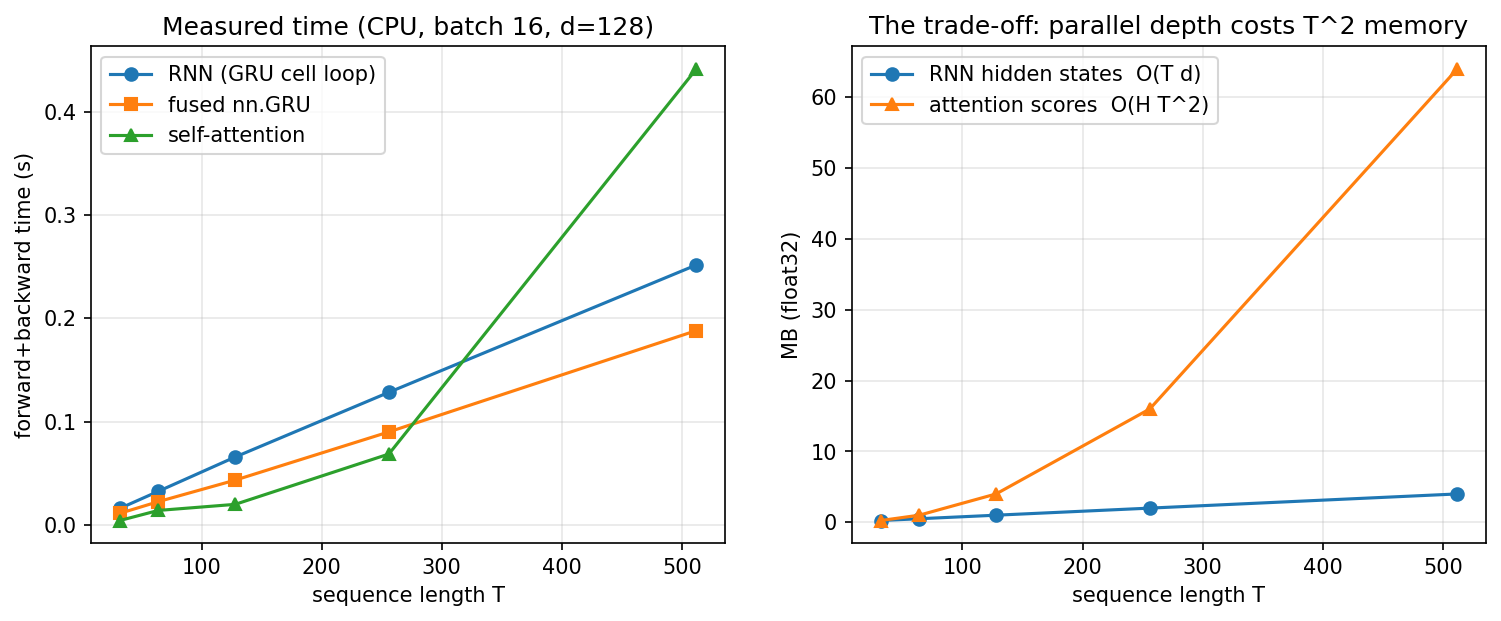

| T | RNN loop fwd+bwd (s) | fused GRU (s) | self-attention (s) | RNN seq. steps | attn seq. steps | RNN hidden states (MB) | attention scores (MB) |
|---|---|---|---|---|---|---|---|
| 32 | 0.016 | 0.011 | 0.004 | 32 | 1 | 0.25 | 0.25 |
| 64 | 0.032 | 0.022 | 0.014 | 64 | 1 | 0.50 | 1.00 |
| 128 | 0.066 | 0.043 | 0.020 | 128 | 1 | 1.00 | 4.00 |
| 256 | 0.128 | 0.090 | 0.069 | 256 | 1 | 2.00 | 16.00 |
| 512 | 0.252 | 0.188 | 0.442 | 512 | 1 | 4.00 | 64.00 |



In [31]:
show("outputs/figures/fig_seq_vs_parallel.png"); print(open("outputs/logs/seq_vs_parallel.md").read())

**How to read it:** the RNN loop's time grows roughly linearly with T because every step has to wait for the previous one. Self-attention does the same job with a few large matrix multiplications, so it can be faster at short and medium lengths when the hardware can run them in parallel, but its T x T score matrices grow quadratically (second plot) and eventually dominate. Report what *your* run shows: where, if anywhere, the lines cross, and why the crossover depends on the hardware (a GPU has far more parallel width than a 2-core CPU, so it moves the crossover). The fused `nn.GRU` is a hand-optimised kernel, so it is shown only for fairness.

## 3. Lesson 02 - self-attention: hand calculation, mask, unit tests

For tokens "I love AI" with hypothetical, already-projected vectors (d_k = d_v = 2) we compute by hand:
`QK^T`, divide by `sqrt(d_k)`, row-wise softmax, multiply by `V`, then add a causal mask and repeat.
`experiments/hand_calc.py` reproduces the paper calculation; **replace the vectors with your own and redo it on paper
for the report** (the handout grades the hand calculation separately).

In [32]:
!python -m experiments.hand_calc

tokens: ['I', 'love', 'AI']
Q =
 tensor([[1., 0.],
        [1., 1.],
        [0., 1.]]) 
K =
 tensor([[1., 0.],
        [0., 1.],
        [1., 1.]]) 
V =
 tensor([[1., 0.],
        [0., 2.],
        [2., 2.]])

1) QK^T =
 tensor([[1., 0., 1.],
        [1., 1., 2.],
        [0., 1., 1.]])

2) QK^T / sqrt(d_k) =
 tensor([[0.7071, 0.0000, 0.7071],
        [0.7071, 0.7071, 1.4142],
        [0.0000, 0.7071, 0.7071]])

3) row-wise softmax weights =
 tensor([[0.4011, 0.1978, 0.4011],
        [0.2483, 0.2483, 0.5035],
        [0.1978, 0.4011, 0.4011]])

4) output = weights @ V =
 tensor([[1.2033, 1.1978],
        [1.2552, 1.5035],
        [1.0000, 1.6044]])

5) causal-masked scores =
 tensor([[0.7071,   -inf,   -inf],
        [0.7071, 0.7071,   -inf],
        [0.0000, 0.7071, 0.7071]])

6) causal weights =
 tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.1978, 0.4011, 0.4011]])

7) causal output =
 tensor([[1.0000, 0.0000],
        [0.5000, 1.0000],
        [1.00

saved outputs/figures/fig01a_hand_calc_printout.png
saved outputs/figures/fig01b_hand_calc_heatmaps.png
saved outputs/figures/fig02_causal_mask.png
B=2 T=10 d_model=128 n_heads=4 d_head=32
input            (2, 10, 128)
q/k/v split      (2, 4, 10, 32)  (B, H, T, d_head)
scores/weights   (2, 4, 10, 10)  (B, H, T, T)
per-head output  (2, 4, 10, 32)
merged           (2, 10, 128)  (B, T, d_model)
final projection (2, 10, 128)

merge_heads(split_heads(z)) == z            : True
merge_heads(...) == concat of the 4 heads: True
attention rows sum to 1 in every head          : True
future weights are exactly 0 in every head     : True

saved outputs/figures/fig03_multihead_shape_trace.png
saved outputs/figures/fig04_positional_encoding.png
checkpoint not found; skipped figures 5, 7 and the architecture diagram


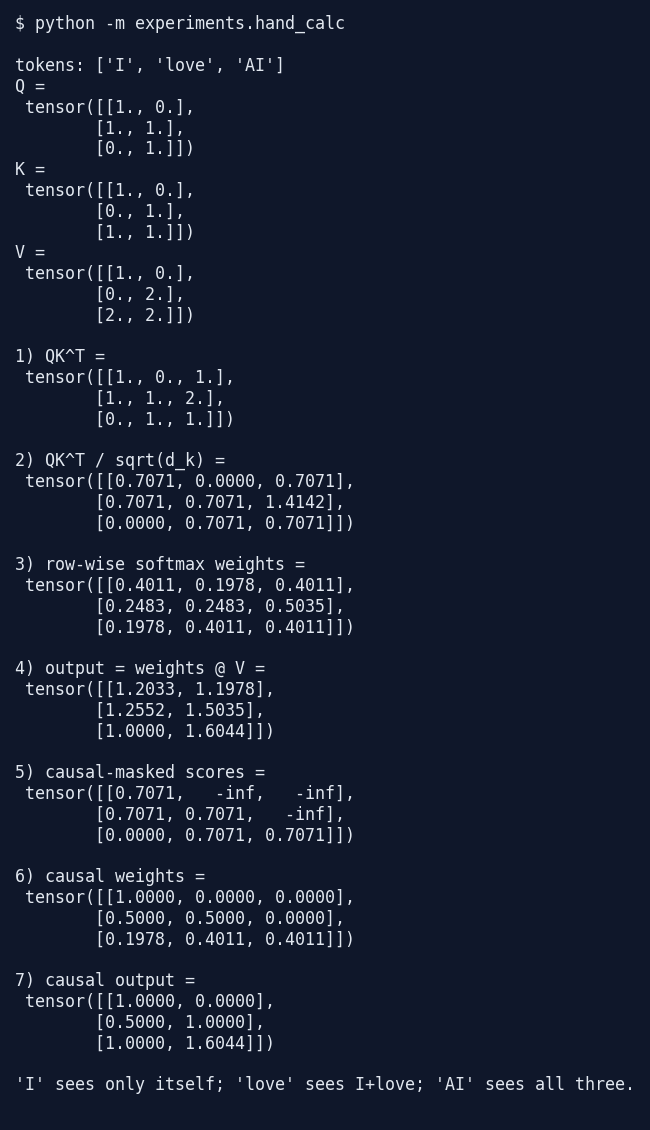

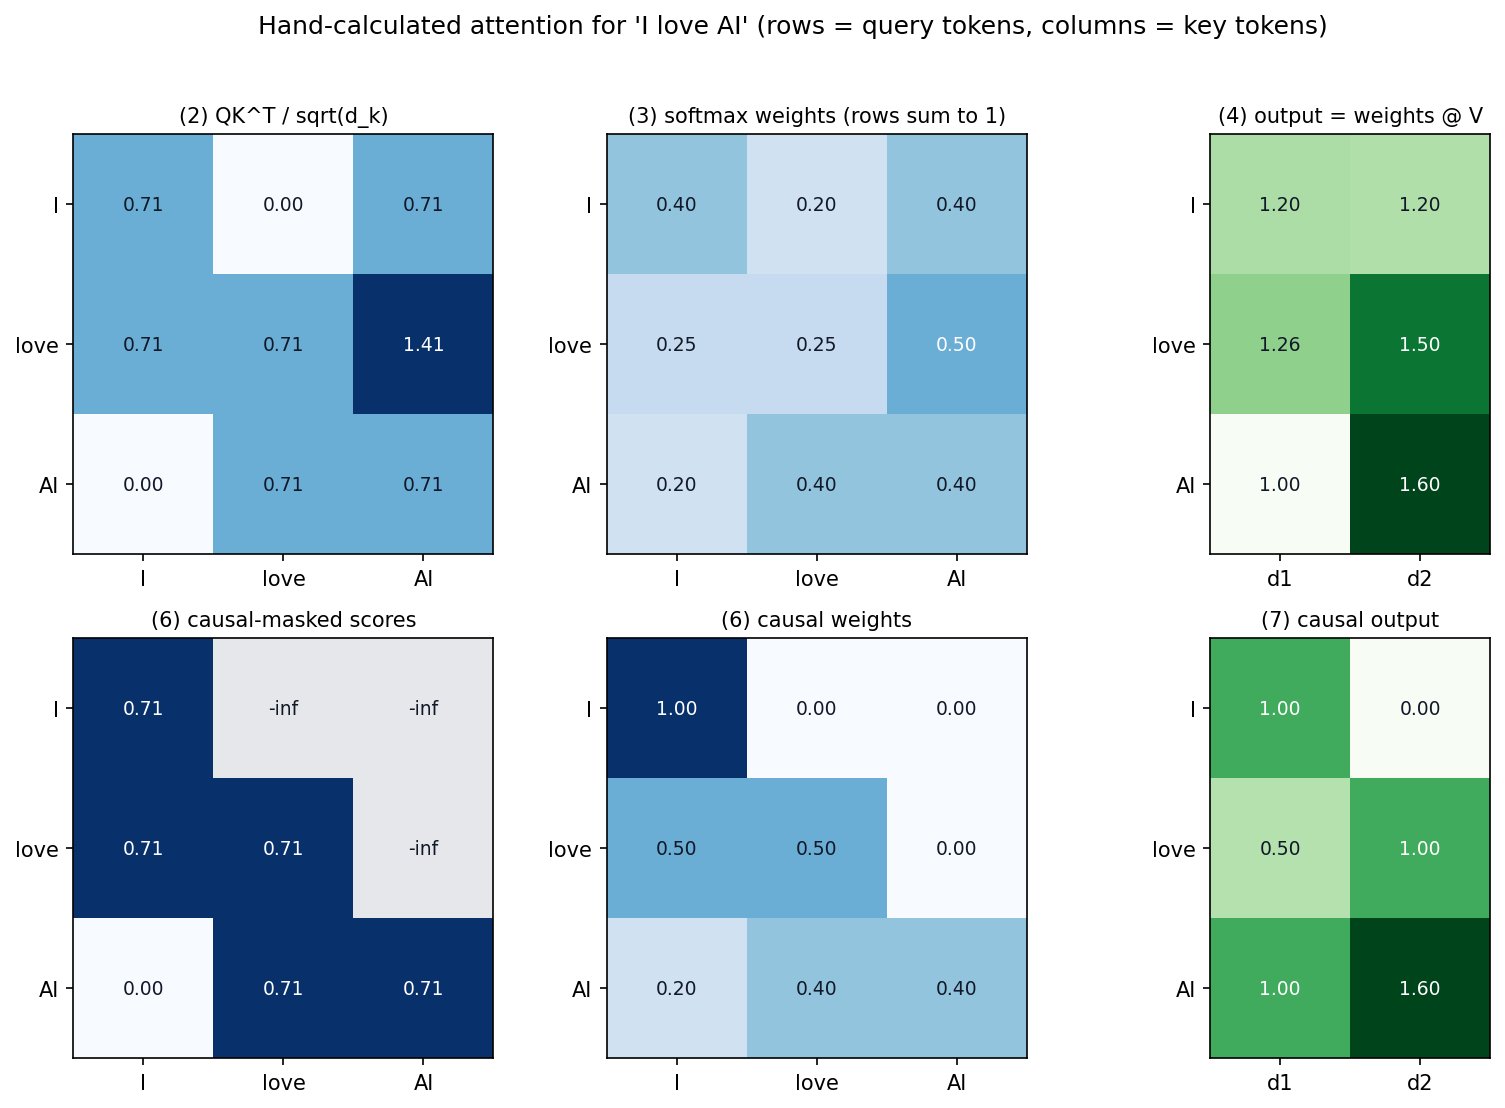

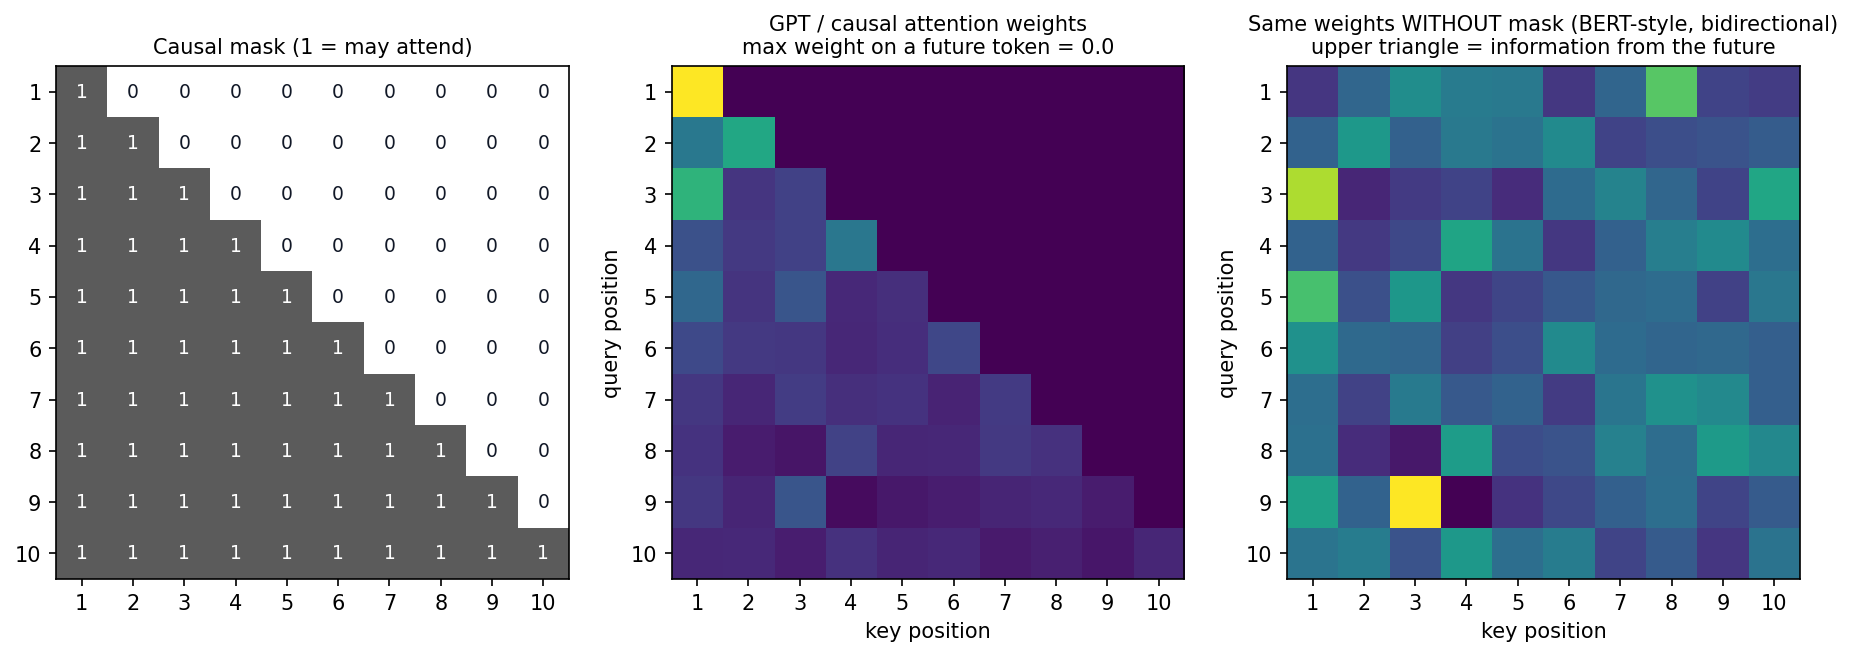

In [33]:
!python -m experiments.attention_visualization
show('outputs/figures/fig01a_hand_calc_printout.png', 'outputs/figures/fig01b_hand_calc_heatmaps.png', 'outputs/figures/fig02_causal_mask.png')

**What changes with the mask?** Without it, row 1 ("I") mixes in information from "love" and "AI" - tokens that, at
generation time, do not exist yet. With it, "I" can only copy itself, "love" averages {I, love}, and "AI" sees all three.
Because the masked entries become `-inf` *before* the softmax, they receive exactly zero weight (not a small weight).

In [34]:
!python -m pytest -q tests/test_attention.py tests/test_mask.py

.....                                                                    [100%]
5 passed in 1.69s


## 4. Lessons 03 and 04 - multi-head attention shapes and positional encoding

Multi-head attention projects the input with `W_Q, W_K, W_V` (each d_model x d_model), reshapes
`(B, T, d_model) -> (B, H, T, d_head)` so every head attends independently, applies attention per head, concatenates the heads
back to `(B, T, d_model)` and mixes them with `W_O`. Attention alone is order-blind (a permutation of the tokens permutes the
output the same way), so we add sinusoidal position vectors to the embeddings.

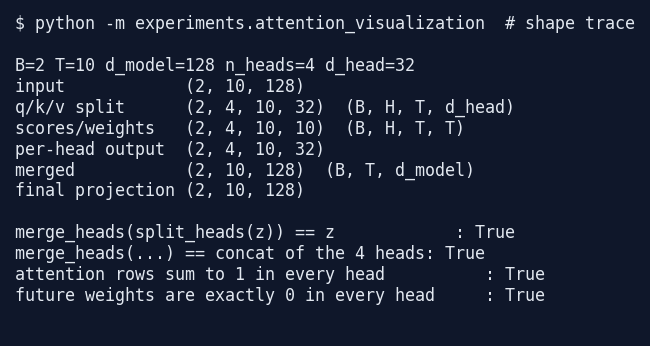

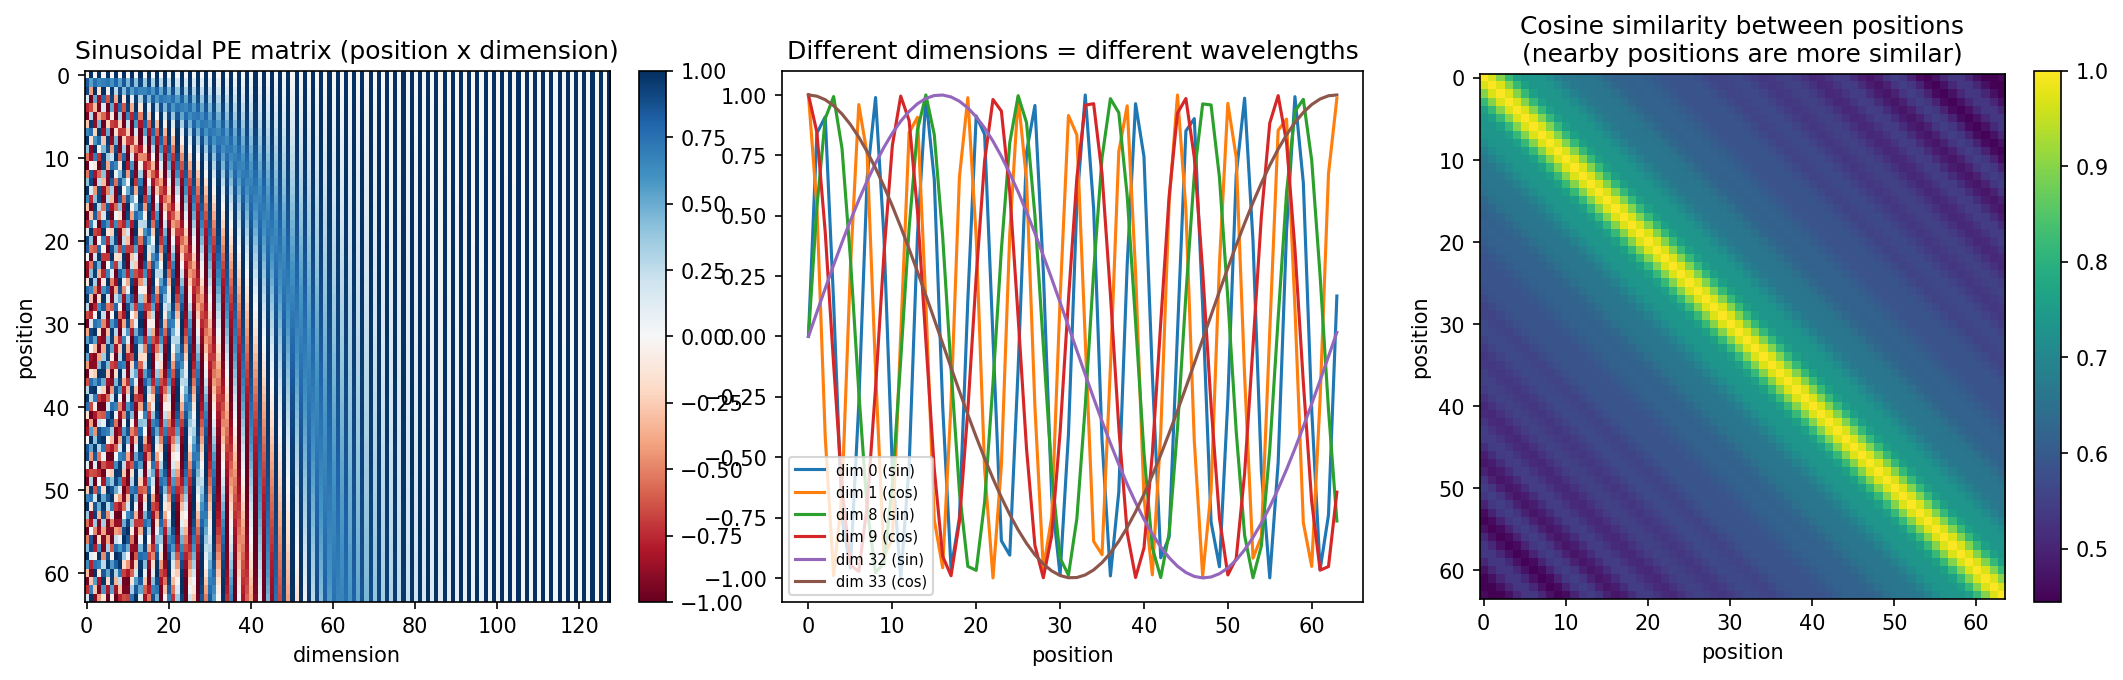

In [35]:
show('outputs/figures/fig03_multihead_shape_trace.png', 'outputs/figures/fig04_positional_encoding.png', width=1000)

## 5. Lesson 06 - BERT-style masked LM vs GPT-style causal LM

Three tiny models share identical blocks and differ only in mask and objective: **A** causal + next-token (GPT),
**B** bidirectional + next-token (what you get if you delete the causal mask), **C** bidirectional + masked-token (BERT).
The test that matters is the *honest* loss: predict token k from tokens < k only, which is what generation actually does.

In [36]:
!python -m experiments.mlm_vs_clm

{
  "uniform_guess_loss": 4.174387269895637,
  "unigram_entropy_loss": 3.3127951622009277,
  "steps_A_B": 400,
  "steps_C_mlm": 1200,
  "A_causal_next_token": {
    "teacher_forced_val_loss": 2.1742872476577757,
    "honest_val_loss": 2.1658622474533815
  },
  "B_bidirectional_next_token": {
    "teacher_forced_val_loss": 0.048525192961096766,
    "honest_val_loss": 9.76687739863138
  },
  "C_bert_mlm": {
    "masked_loss_both_sides": 2.5844883918762207,
    "masked_loss_left_context_only": 3.1826014518737793
  }
}
saved outputs/figures/fig_mlm_vs_clm.png


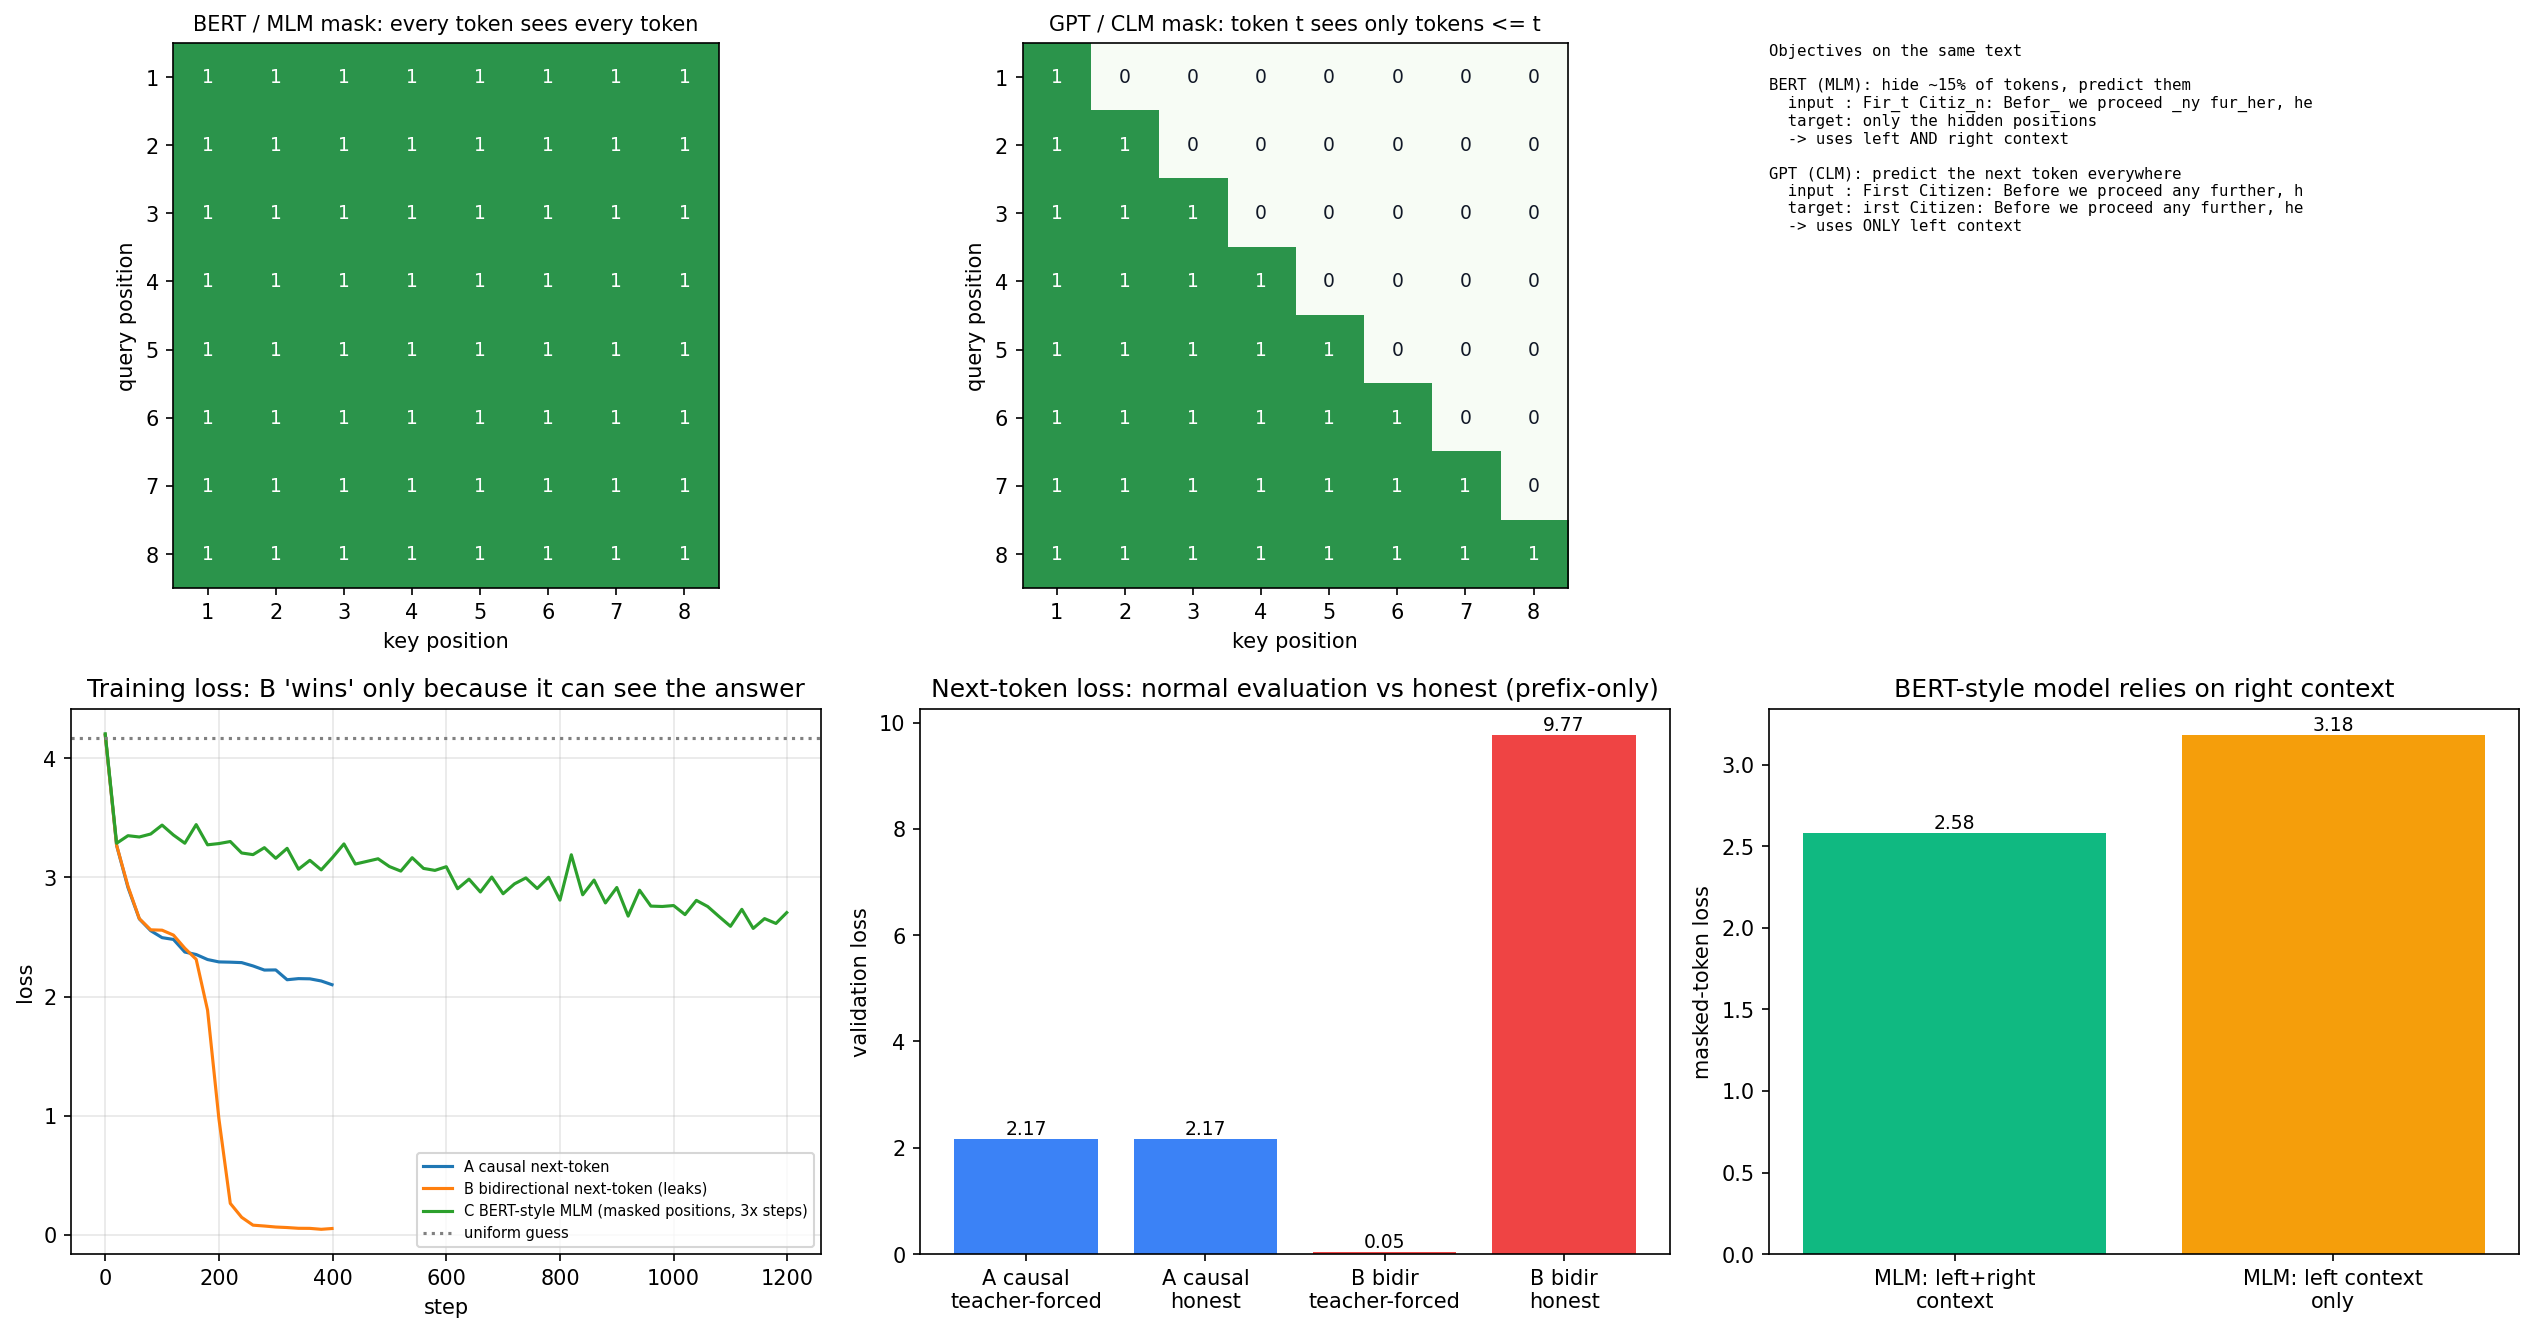

In [37]:
show("outputs/figures/fig_mlm_vs_clm.png", width=1100)

**Interpretation to write up:** model B reaches a tiny training loss because position t can read token t+1 - the answer. Its
"honest" loss is bad, and it cannot generate. Model C is a good gap-filler but its loss worsens when the right context is
hidden, so it is not a left-to-right generator. Only A's training objective matches how it is used at inference.

## 6. Milestone 4 gate - overfit a tiny batch before the long run

If gradients, the shifted targets or the mask were wrong, the model could not memorise 4 short sequences.
Loss should fall from about ln(65) = 4.17 to near zero.

In [38]:
import torch
from src.gpt import GPTConfig, MiniGPT
from src.utils import set_seed, get_device
set_seed(0); dev = get_device()
m = MiniGPT(GPTConfig(vocab_size=tok.vocab_size, context_length=32, d_model=64, n_heads=4, n_layers=2, dropout=0.0)).to(dev)
ids = torch.tensor(tok.encode(text[:2000]), dtype=torch.long)
batch = torch.stack([ids[i:i+33] for i in range(0, 132, 33)]).to(dev)       # 4 fixed sequences
x, y = batch[:, :-1], batch[:, 1:]                                           # y[t] is the NEXT token after x[t]
opt = torch.optim.AdamW(m.parameters(), lr=3e-3)
for step in range(201):
    loss = m(x, y)[1]; opt.zero_grad(); loss.backward(); opt.step()
    if step % 40 == 0: print(f"step {step:3d}  loss {loss.item():.4f}")
assert loss.item() < 0.3, "overfit gate failed"
print("overfit gate passed")

step   0  loss 4.2176
step  40  loss 0.3631
step  80  loss 0.0112
step 120  loss 0.0055
step 160  loss 0.0037
step 200  loss 0.0028
overfit gate passed


## 7. Model configuration

`configs/colab_gpu.yaml`: context 128, d_model 256, 4 heads, 4 layers, FFN 4 x d_model = 1024, dropout 0.1, AdamW,
lr 6e-4 with 150 warm-up steps and cosine decay, batch 64, 4000 steps (about 33 epochs of the 1M-character training split).
These are the handout's starting values with d_model = 256; the resulting size is about 3.2M parameters. The learning rate was
raised from the suggested 3e-4 because the run is short; the other starting values were kept.

In [39]:
!cat configs/colab_gpu.yaml

# Colab T4 configuration: ~3.2M parameters (d_model 256, 4 layers) as in the handout's example output.
model:
  context_length: 128
  d_model: 256
  n_heads: 4
  n_layers: 4
  ffn_mult: 4
  dropout: 0.1
  tie_weights: false
  pos_type: sinusoidal
train:
  optimizer: adamw
  lr: 0.0006
  weight_decay: 0.01
  batch_size: 64
  max_steps: 4000
  eval_interval: 250
  eval_iters: 40
  warmup_steps: 150
  seed: 1337
  val_frac: 0.1
data:
  path: data/input.txt
generate:
  temperature: 0.8
  top_k: 40
  max_new_tokens: 300


## 8. Train the baseline (Lesson 07) and inspect it

The loop samples random windows, builds `x = data[i:i+T]` and `y = data[i+1:i+T+1]`, and minimises cross-entropy between
`logits[t]` and `y[t]`. It logs train/validation loss, learning rate, epoch, tokens/s and a **sample generation at every
evaluation**, then saves `checkpoints/baseline.pt` and `outputs/logs/baseline.json`.

In [40]:
!python -m src.train --config configs/colab_gpu.yaml --tag baseline --overrides $EXTRA

device=cuda vocab=65 params=3.193M train_tokens=1003854 val_tokens=111540
{'step': 0, 'epoch': 0.0, 'train_loss': 4.254, 'val_loss': 4.2503, 'lr': 0.0, 'elapsed_s': 2.0779, 'tokens_per_s': 0.0}
  sample: 'ROMEO:!YfzxfRkR\nkNwc.wj,ST,O.lT,eHsK\nja!PjJTMBFzA!3e.-SGJJ-33jM:FhlIhduhX:YjXJtpXNNuwc'
{'step': 250, 'epoch': 2.0401, 'train_loss': 2.135, 'val_loss': 2.161, 'lr': 0.0006, 'elapsed_s': 20.7106, 'tokens_per_s': 127318.5695}
  sample: 'ROMEO:\nAnd the we the sise by foree lomp, sto thourd,\nThiM in spre mute his wis coune '
{'step': 500, 'epoch': 4.0803, 'train_loss': 1.7704, 'val_loss': 1.8965, 'lr': 0.0006, 'elapsed_s': 39.3866, 'tokens_per_s': 126072.3362}
  sample: 'ROMEO:\nNow the ring, the did make a love feor and to to beed,\nFir what, by for moth so'
{'step': 750, 'epoch': 6.1204, 'train_loss': 1.5932, 'val_loss': 1.7708, 'lr': 0.0006, 'elapsed_s': 58.7275, 'tokens_per_s': 124105.656}
  sample: 'ROMEO:\nAnd stard friends, for I lost, he him.\nNay that of him provose to his th

saved outputs/figures/fig01a_hand_calc_printout.png
saved outputs/figures/fig01b_hand_calc_heatmaps.png
saved outputs/figures/fig02_causal_mask.png
B=2 T=10 d_model=128 n_heads=4 d_head=32
input            (2, 10, 128)
q/k/v split      (2, 4, 10, 32)  (B, H, T, d_head)
scores/weights   (2, 4, 10, 10)  (B, H, T, T)
per-head output  (2, 4, 10, 32)
merged           (2, 10, 128)  (B, T, d_model)
final projection (2, 10, 128)

merge_heads(split_heads(z)) == z            : True
merge_heads(...) == concat of the 4 heads: True
attention rows sum to 1 in every head          : True
future weights are exactly 0 in every head     : True

saved outputs/figures/fig03_multihead_shape_trace.png
saved outputs/figures/fig04_positional_encoding.png
MiniGPT  vocab_size=65  context_length=128  d_model=256  n_heads=4  n_layers=4  ffn_dim=1024  dropout=0.1  pos=sinusoidal

module                                detail                                          params
--------------------------------------------

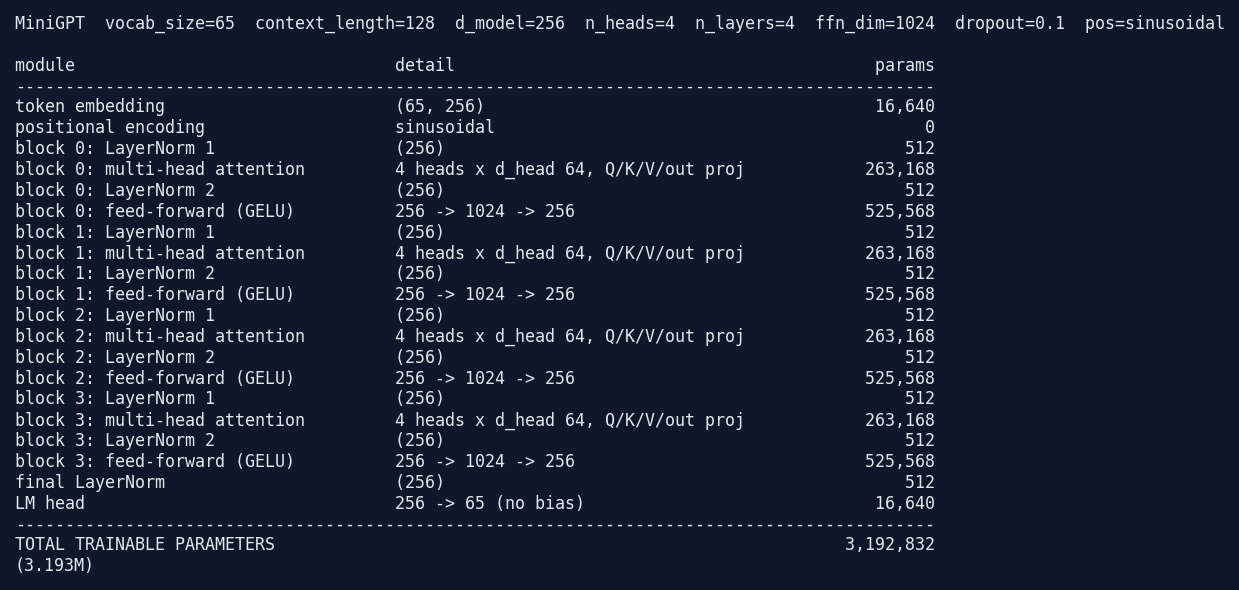

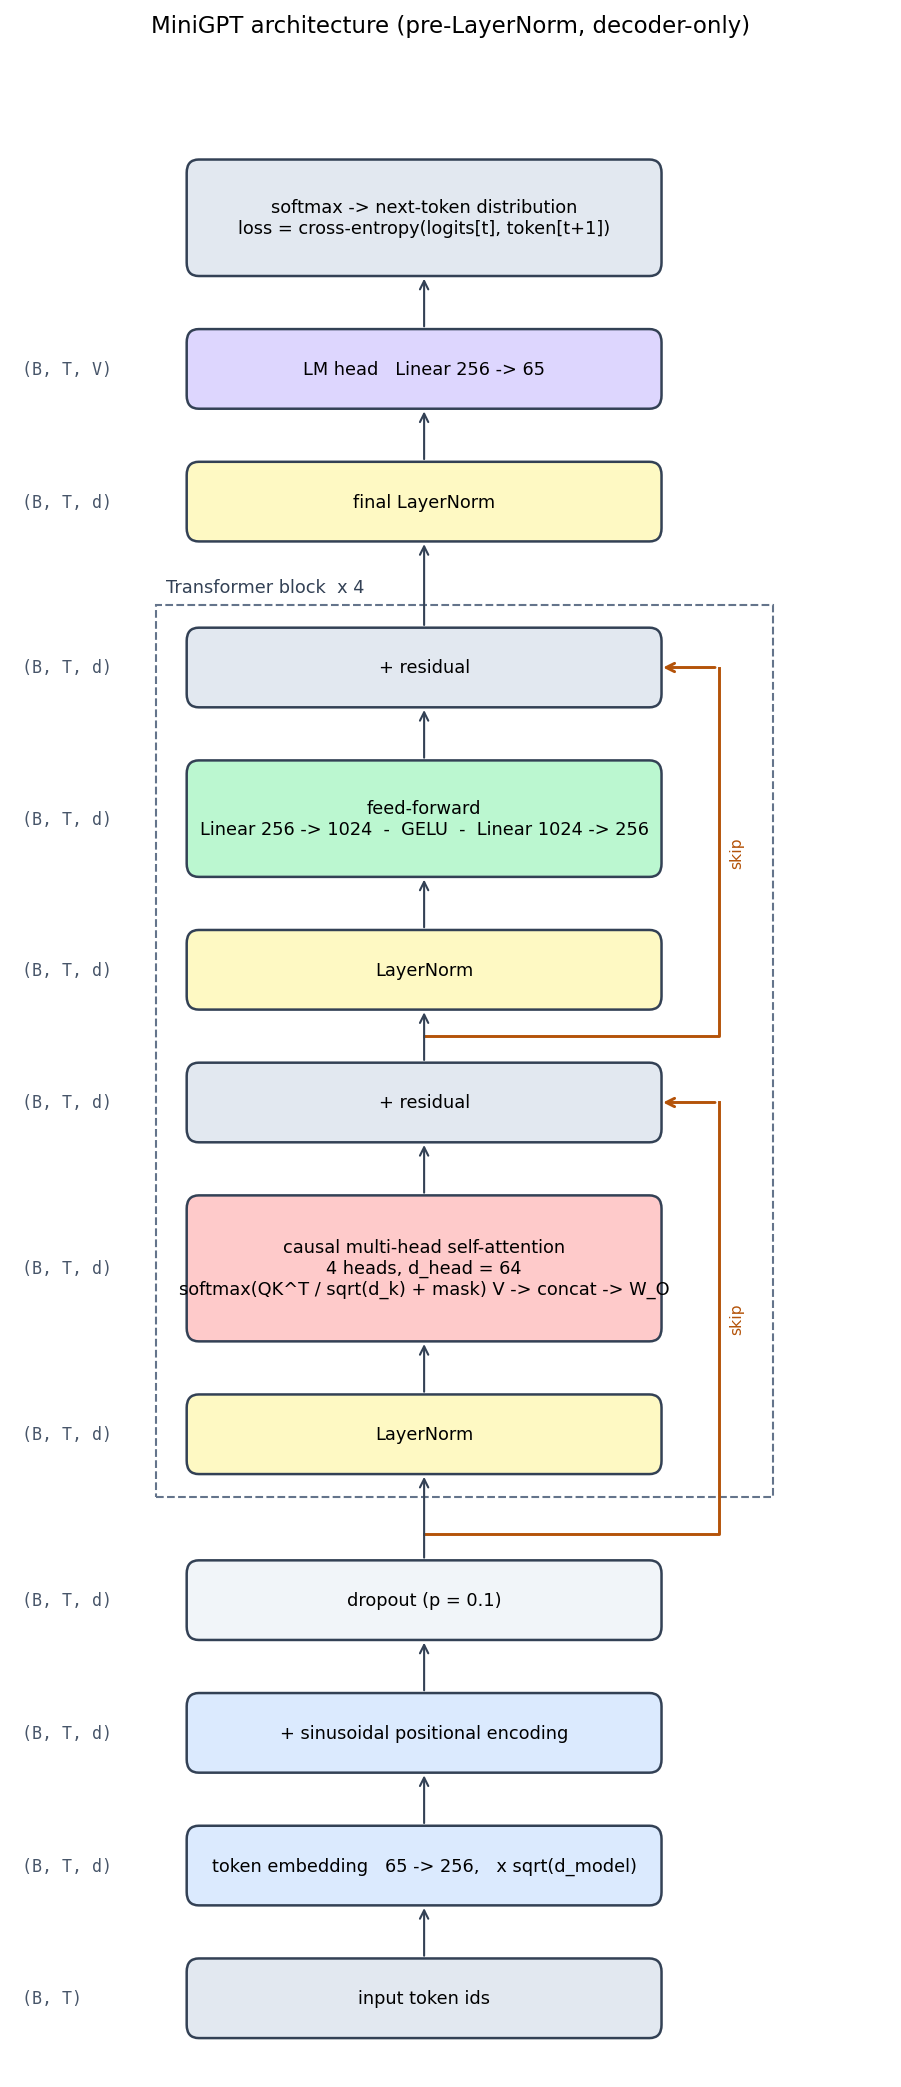

In [41]:
!python -m experiments.attention_visualization
show('outputs/figures/fig05_model_summary.png', 'outputs/figures/fig_architecture.png', width=800)

val loss 1.4838 | perplexity 4.41 | bits/char 2.141 | causal check max |dlogit| = 0.00e+00
saved outputs/figures/fig08_generation_samples.png
greedy (T=0)   distinct-1 0.20  distinct-2 0.26
T=0.5          distinct-1 0.74  distinct-2 0.96
T=0.8          distinct-1 0.85  distinct-2 0.98
T=1.2          distinct-1 0.86  distinct-2 0.98
saved outputs/figures/fig10a_cli_call.png
saved outputs/figures/fig10b_api_call.png
saved evaluation.json


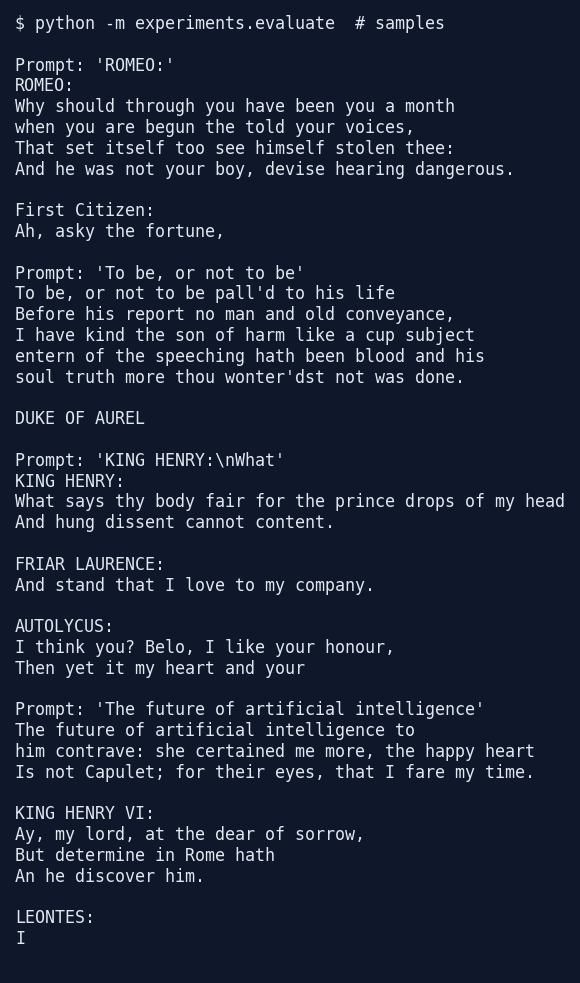

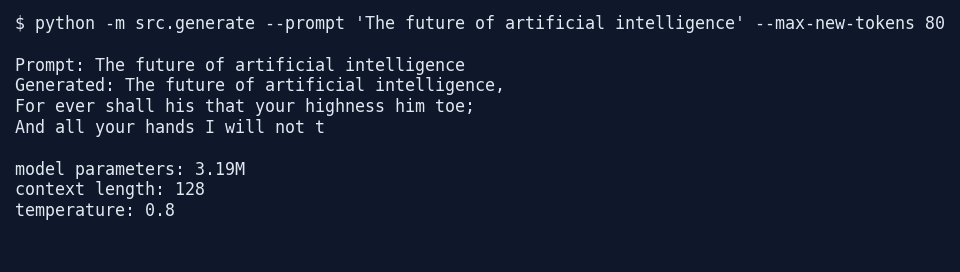

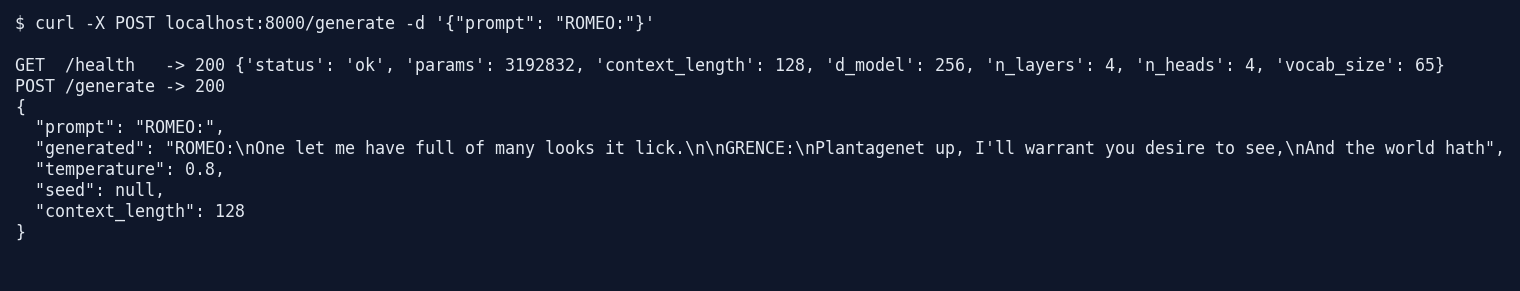

In [42]:
!python -m experiments.evaluate --checkpoint checkpoints/baseline.pt
show('outputs/figures/fig08_generation_samples.png', 'outputs/figures/fig10a_cli_call.png', 'outputs/figures/fig10b_api_call.png', width=1000)

In [43]:
print(open("outputs/samples/samples.md").read())

# Generated samples (temperature 0.8, top-k 40, fixed prompts, seed 1234)

## Prompt: `'ROMEO:'`
```
ROMEO:
Why should through you have been you a month
when you are begun the told your voices,
That set itself too see himself stolen thee:
And he was not your boy, devise hearing dangerous.

First Citizen:
Ah, asky the fortune,
```

## Prompt: `'To be, or not to be'`
```
To be, or not to be pall'd to his life
Before his report no man and old conveyance,
I have kind the son of harm like a cup subject
entern of the speeching hath been blood and his
soul truth more thou wonter'dst not was done.

DUKE OF AUREL
```

## Prompt: `'KING HENRY:\nWhat'`
```
KING HENRY:
What says thy body fair for the prince drops of my head
And hung dissent cannot content.

FRIAR LAURENCE:
And stand that I love to my company.

AUTOLYCUS:
I think you? Belo, I like your honour,
Then yet it my heart and your 
```

## Prompt: `'The future of artificial intelligence'`
```
The future of artificial intelligence to
him co

### Figure 7 - what is the trained model actually attending to?

Each panel is one head in one layer: rows are query characters, columns are the characters they look at. Everything above
the diagonal is zero (the causal mask). The statistics file reports, per head, how much weight goes to the current character,
the previous character, and the first character - evidence of real behaviour rather than only a loss number.

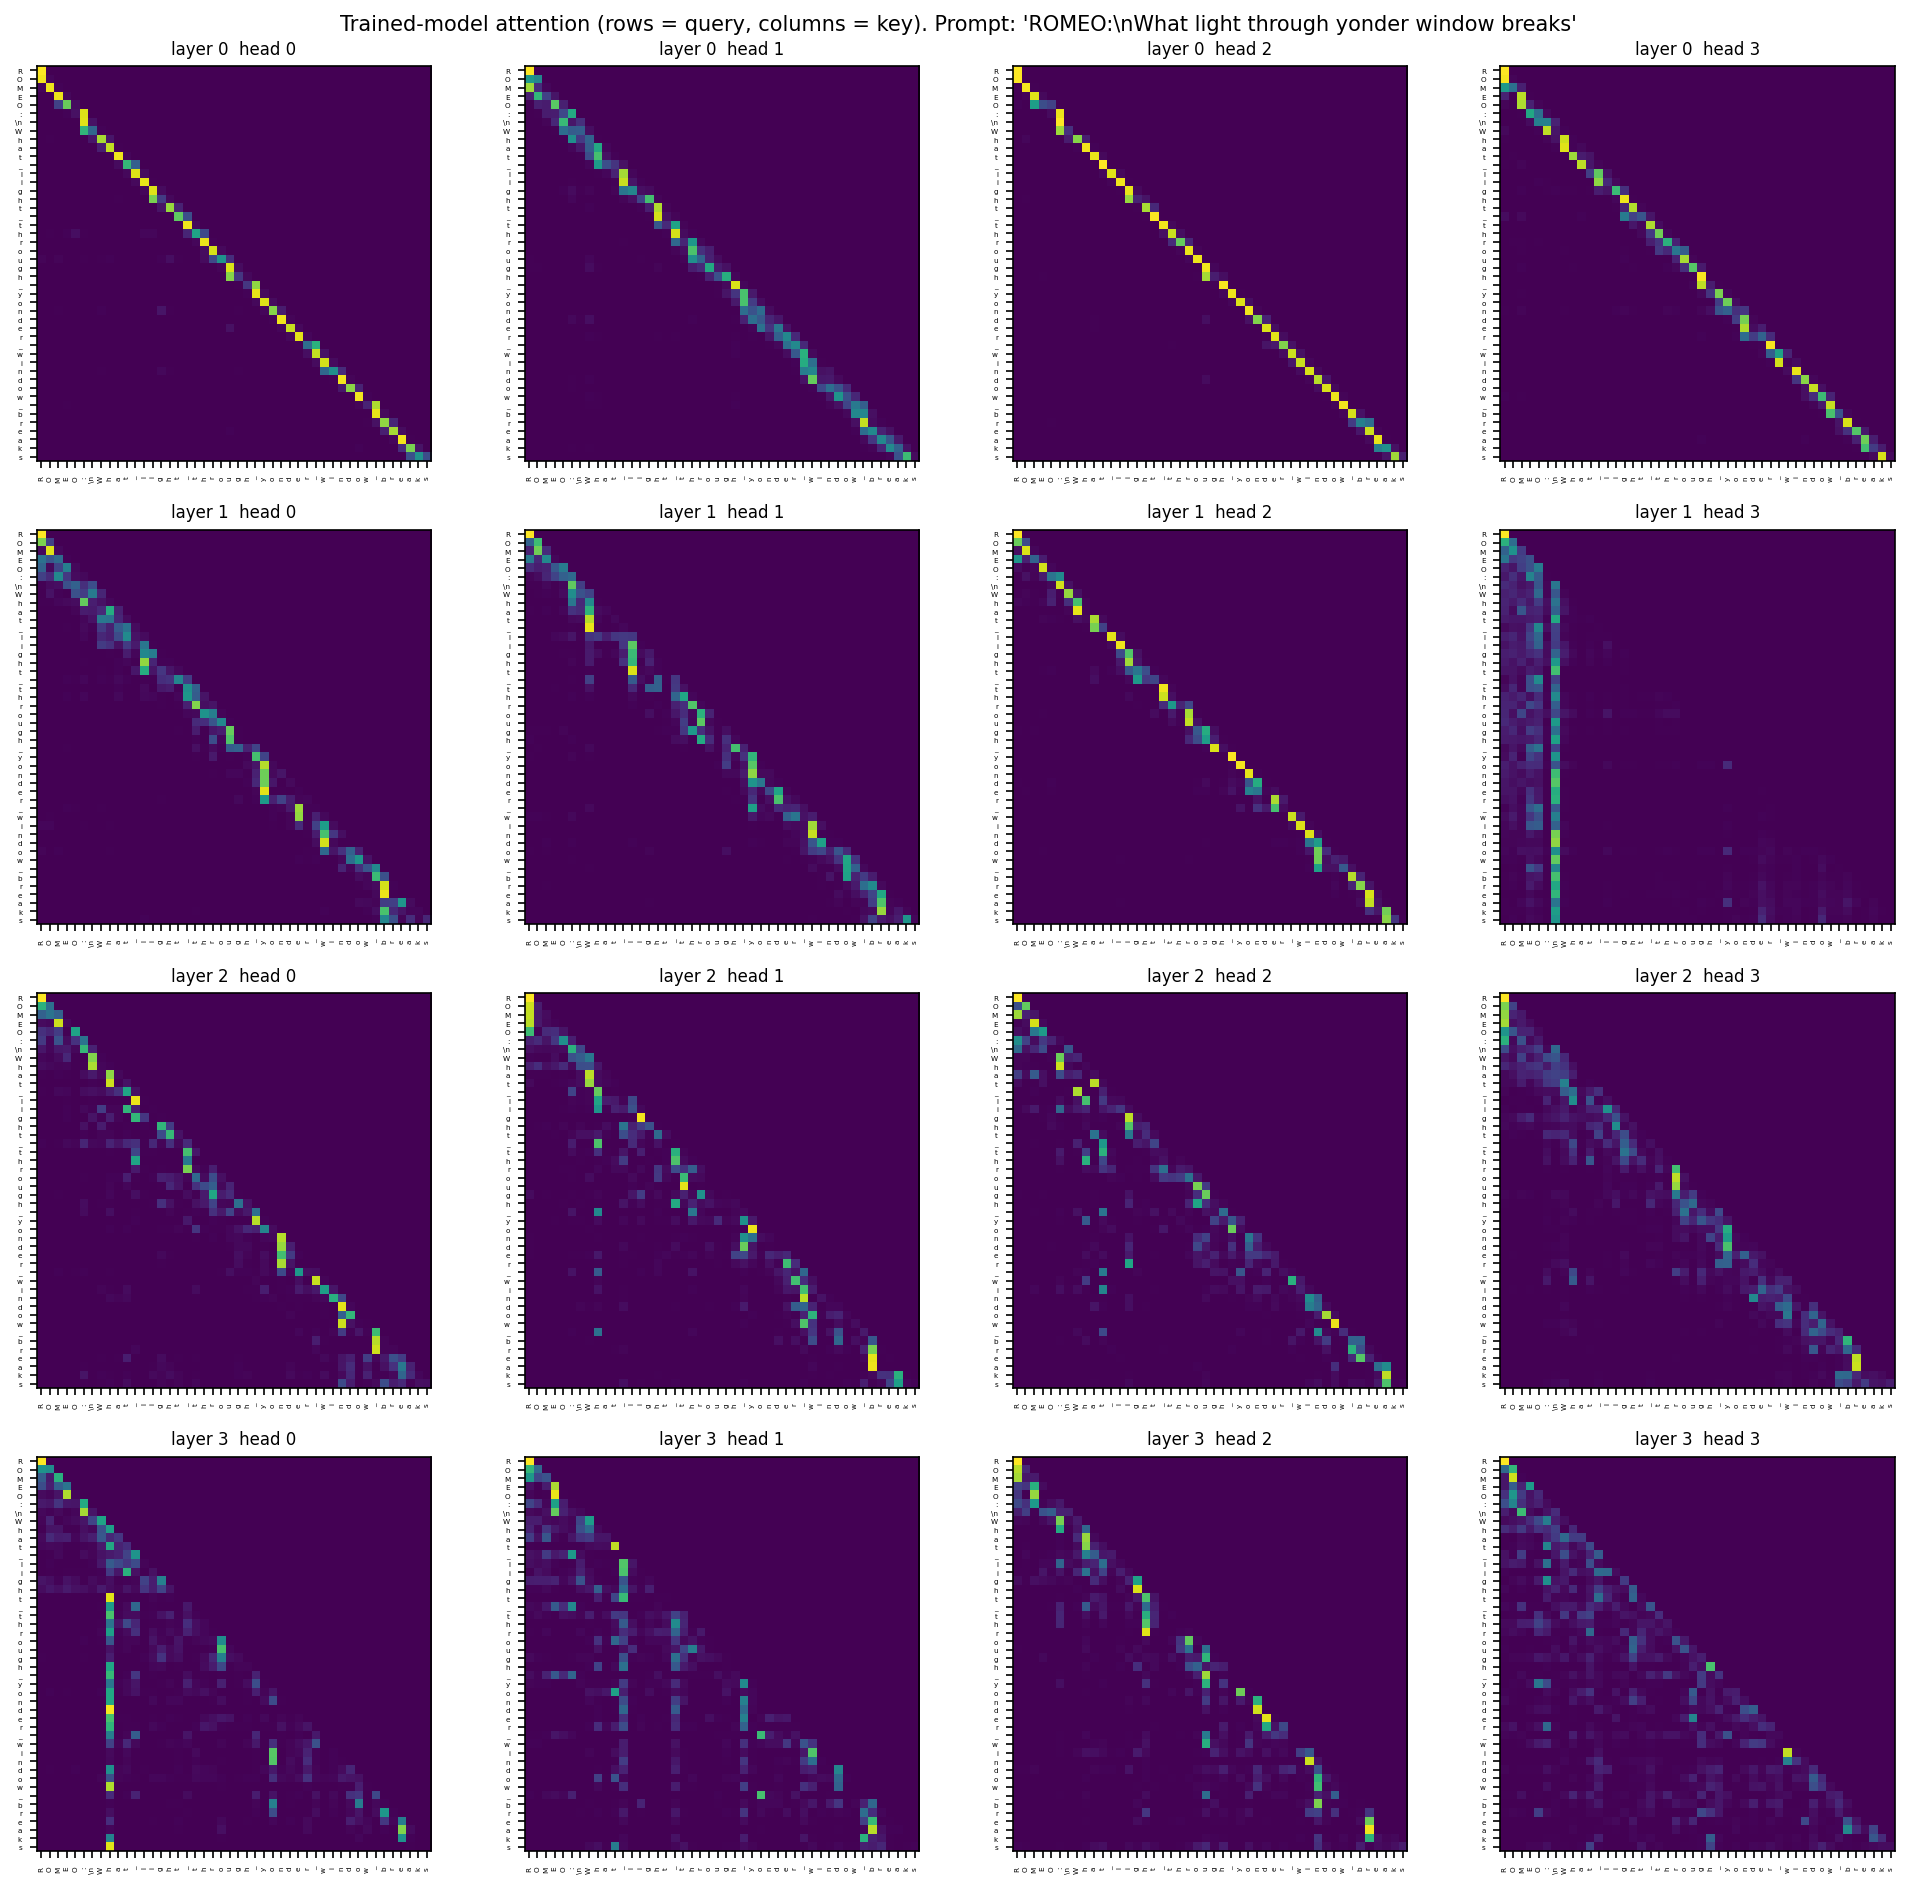

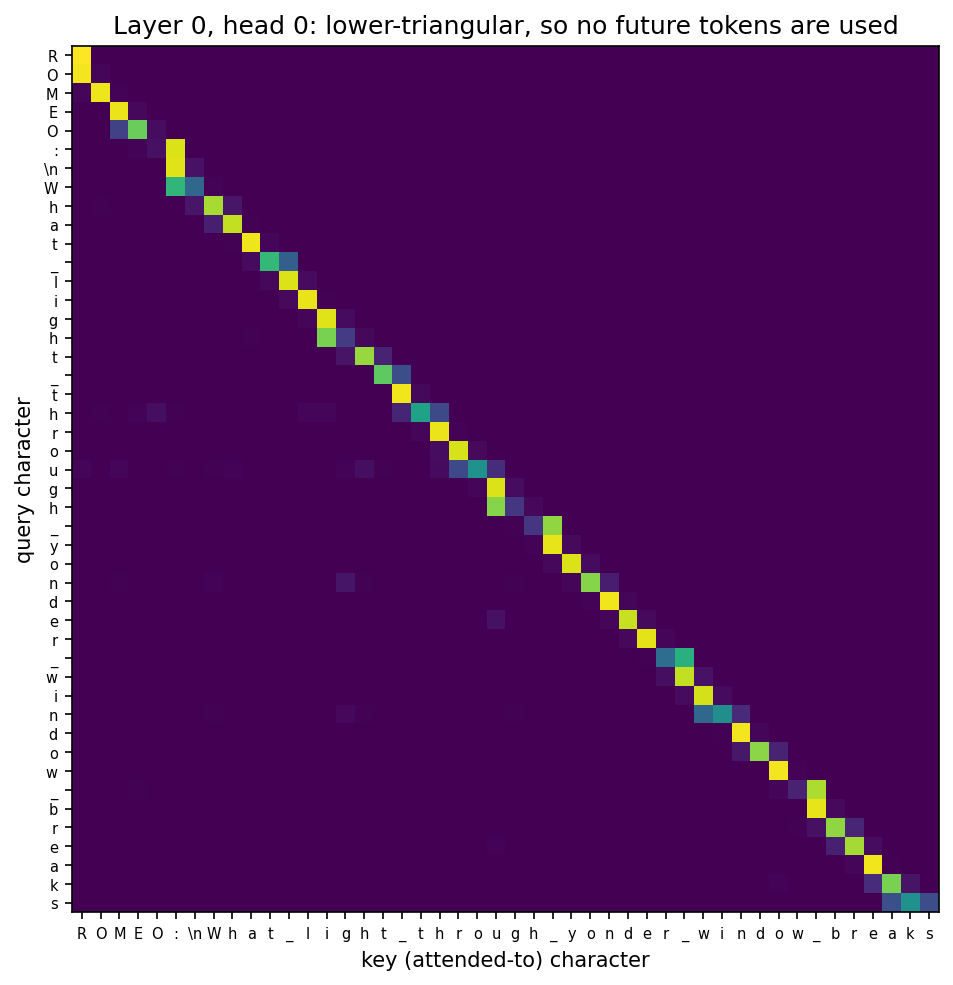

L0H0 {'self': 0.145, 'previous_token': 0.765, 'first_token': 0.023, 'mean_distance': 1.121}
L0H1 {'self': 0.091, 'previous_token': 0.343, 'first_token': 0.034, 'mean_distance': 1.939}
L0H2 {'self': 0.083, 'previous_token': 0.827, 'first_token': 0.023, 'mean_distance': 1.103}
L0H3 {'self': 0.069, 'previous_token': 0.575, 'first_token': 0.039, 'mean_distance': 1.541}
L1H0 {'self': 0.09, 'previous_token': 0.31, 'first_token': 0.039, 'mean_distance': 2.319}
L1H1 {'self': 0.111, 'previous_token': 0.296, 'first_token': 0.023, 'mean_distance': 2.466}
L1H2 {'self': 0.063, 'previous_token': 0.552, 'first_token': 0.031, 'mean_distance': 1.61}
L1H3 {'self': 0.06, 'previous_token': 0.057, 'first_token': 0.076, 'mean_distance': 16.579}
L2H0 {'self': 0.139, 'previous_token': 0.372, 'first_token': 0.032, 'mean_distance': 2.909}
L2H1 {'self': 0.076, 'previous_token': 0.22, 'first_token': 0.083, 'mean_distance': 4.021}
L2H2 {'self': 0.098, 'previous_token': 0.296, 'first_token': 0.05, 'mean_distance': 

In [44]:
show("outputs/figures/fig07_trained_attention_grid.png", "outputs/figures/fig07b_trained_attention_head.png", width=1000)
import json
st = json.load(open("outputs/logs/attention_stats.json"))
for k, v in st.items(): print(k, {a: round(b, 3) for a, b in v.items()})

## 9. Ablation study (three required controlled experiments + one optional)

Each run changes **one** factor of the baseline and keeps everything else (seed, steps, learning rate, data split) fixed:
depth 2/4/6, heads 2/4/8, context 64/128/256, and sinusoidal vs learned positions. For the context-length runs the batch size is
rescaled automatically so every step sees the same number of tokens (`batch x context = 8192`); otherwise longer contexts would
simply get more training data per step. Validation loss is measured on the **whole** validation split with non-overlapping
windows.

In [45]:
RUNS = {"depth2": "n_layers=2", "depth6": "n_layers=6", "heads2": "n_heads=2", "heads8": "n_heads=8",
        "ctx64": "context_length=64", "ctx256": "context_length=256", "learnedpos": "pos_type=learned"}
for tag, ov in RUNS.items():
    if os.path.exists(f"outputs/logs/{tag}.json") and not QUICK:
        print("already trained:", tag); continue
    print("=" * 30, tag, ov)
    !python -m src.train --config configs/colab_gpu.yaml --tag $tag --overrides $ov $EXTRA

============================== depth2 n_layers=2
device=cuda vocab=65 params=1.613M train_tokens=1003854 val_tokens=111540
{'step': 0, 'epoch': 0.0, 'train_loss': 4.178, 'val_loss': 4.1817, 'lr': 0.0, 'elapsed_s': 1.3136, 'tokens_per_s': 0.0}
  sample: "ROMEO:yqfzxfMfLbrNdc.wdNZTxeLlL,ebsKvb:!YeYkbubeB$3:X-SvgOP33&MBd?gL3aUhX:YVXWth&Mz'wq"
{'step': 250, 'epoch': 2.0401, 'train_loss': 2.1713, 'val_loss': 2.1946, 'lr': 0.0006, 'elapsed_s': 13.0371, 'tokens_per_s': 201268.4459}
  sample: 'ROMEO:\nA fory incir, and were id, roll onour, ard thou willy\nI sou aly cou discin weai'
{'step': 500, 'epoch': 4.0803, 'train_loss': 1.8464, 'val_loss': 1.9638, 'lr': 0.0006, 'elapsed_s': 25.1239, 'tokens_per_s': 196616.5016}
  sample: "ROMEO:\nAnd 'ty my so love deveng.\n\nDUKE OMBENTES:\nA but be stath father gain.\n\n\nDUKE V"
{'step': 750, 'epoch': 6.1204, 'train_loss': 1.6693, 'val_loss': 1.827, 'lr': 0.0006, 'elapsed_s': 37.4123, 'tokens_per_s': 193642.47}
  sample: 'ROMEO:\nThou cannce the poose

| Experiment | Setting | Params | Batch x ctx | Final train loss | Val loss | Val ppl | Train time (s) | Tokens/s | Peak RSS (MB) |
|---|---|---|---|---|---|---|---|---|---|
| Depth (n_layers) | 2 | 1,613,312 | 64x128 | 1.320 | 1.547 | 4.70 | 163 | 201,414 | 439 |
| Depth (n_layers) | 4 | 3,192,832 | 64x128 | 1.210 | 1.484 | 4.41 | 306 | 107,224 | 794 |
| Depth (n_layers) | 6 | 4,772,352 | 64x128 | 1.148 | 1.466 | 4.33 | 475 | 68,955 | 1148 |
| Heads (n_heads) | 2 | 3,192,832 | 64x128 | 1.226 | 1.480 | 4.39 | 304 | 107,704 | 722 |
| Heads (n_heads) | 4 | 3,192,832 | 64x128 | 1.210 | 1.484 | 4.41 | 306 | 107,224 | 794 |
| Heads (n_heads) | 8 | 3,192,832 | 64x128 | 1.191 | 1.476 | 4.37 | 352 | 93,107 | 938 |
| Context length | 64 | 3,192,832 | 128x64 | 1.233 | 1.500 | 4.48 | 298 | 109,934 | 722 |
| Context length | 128 | 3,192,832 | 64x128 | 1.210 | 1.484 | 4.41 | 306 | 107,224 | 794 |
| Context length | 256 | 3,192,832 | 32x256 | 1.200 | 1.479 | 4.39 | 363 | 90,261 | 938 |
| Position me

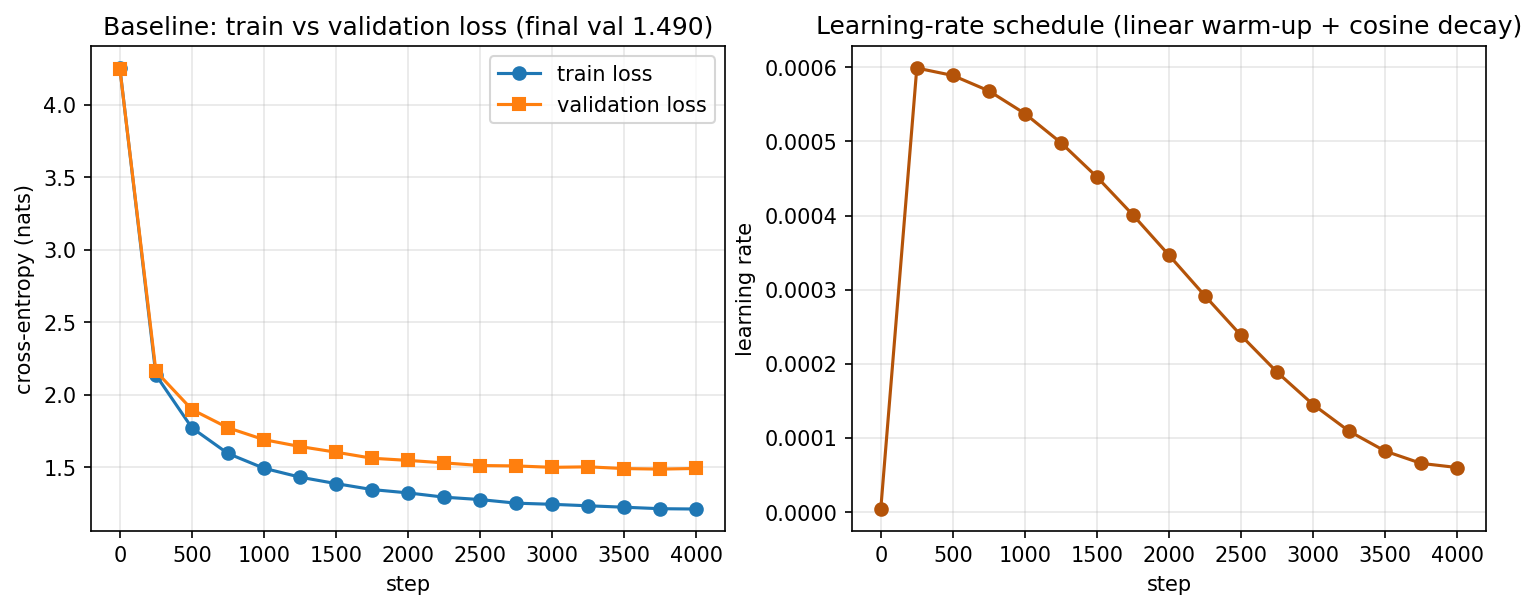

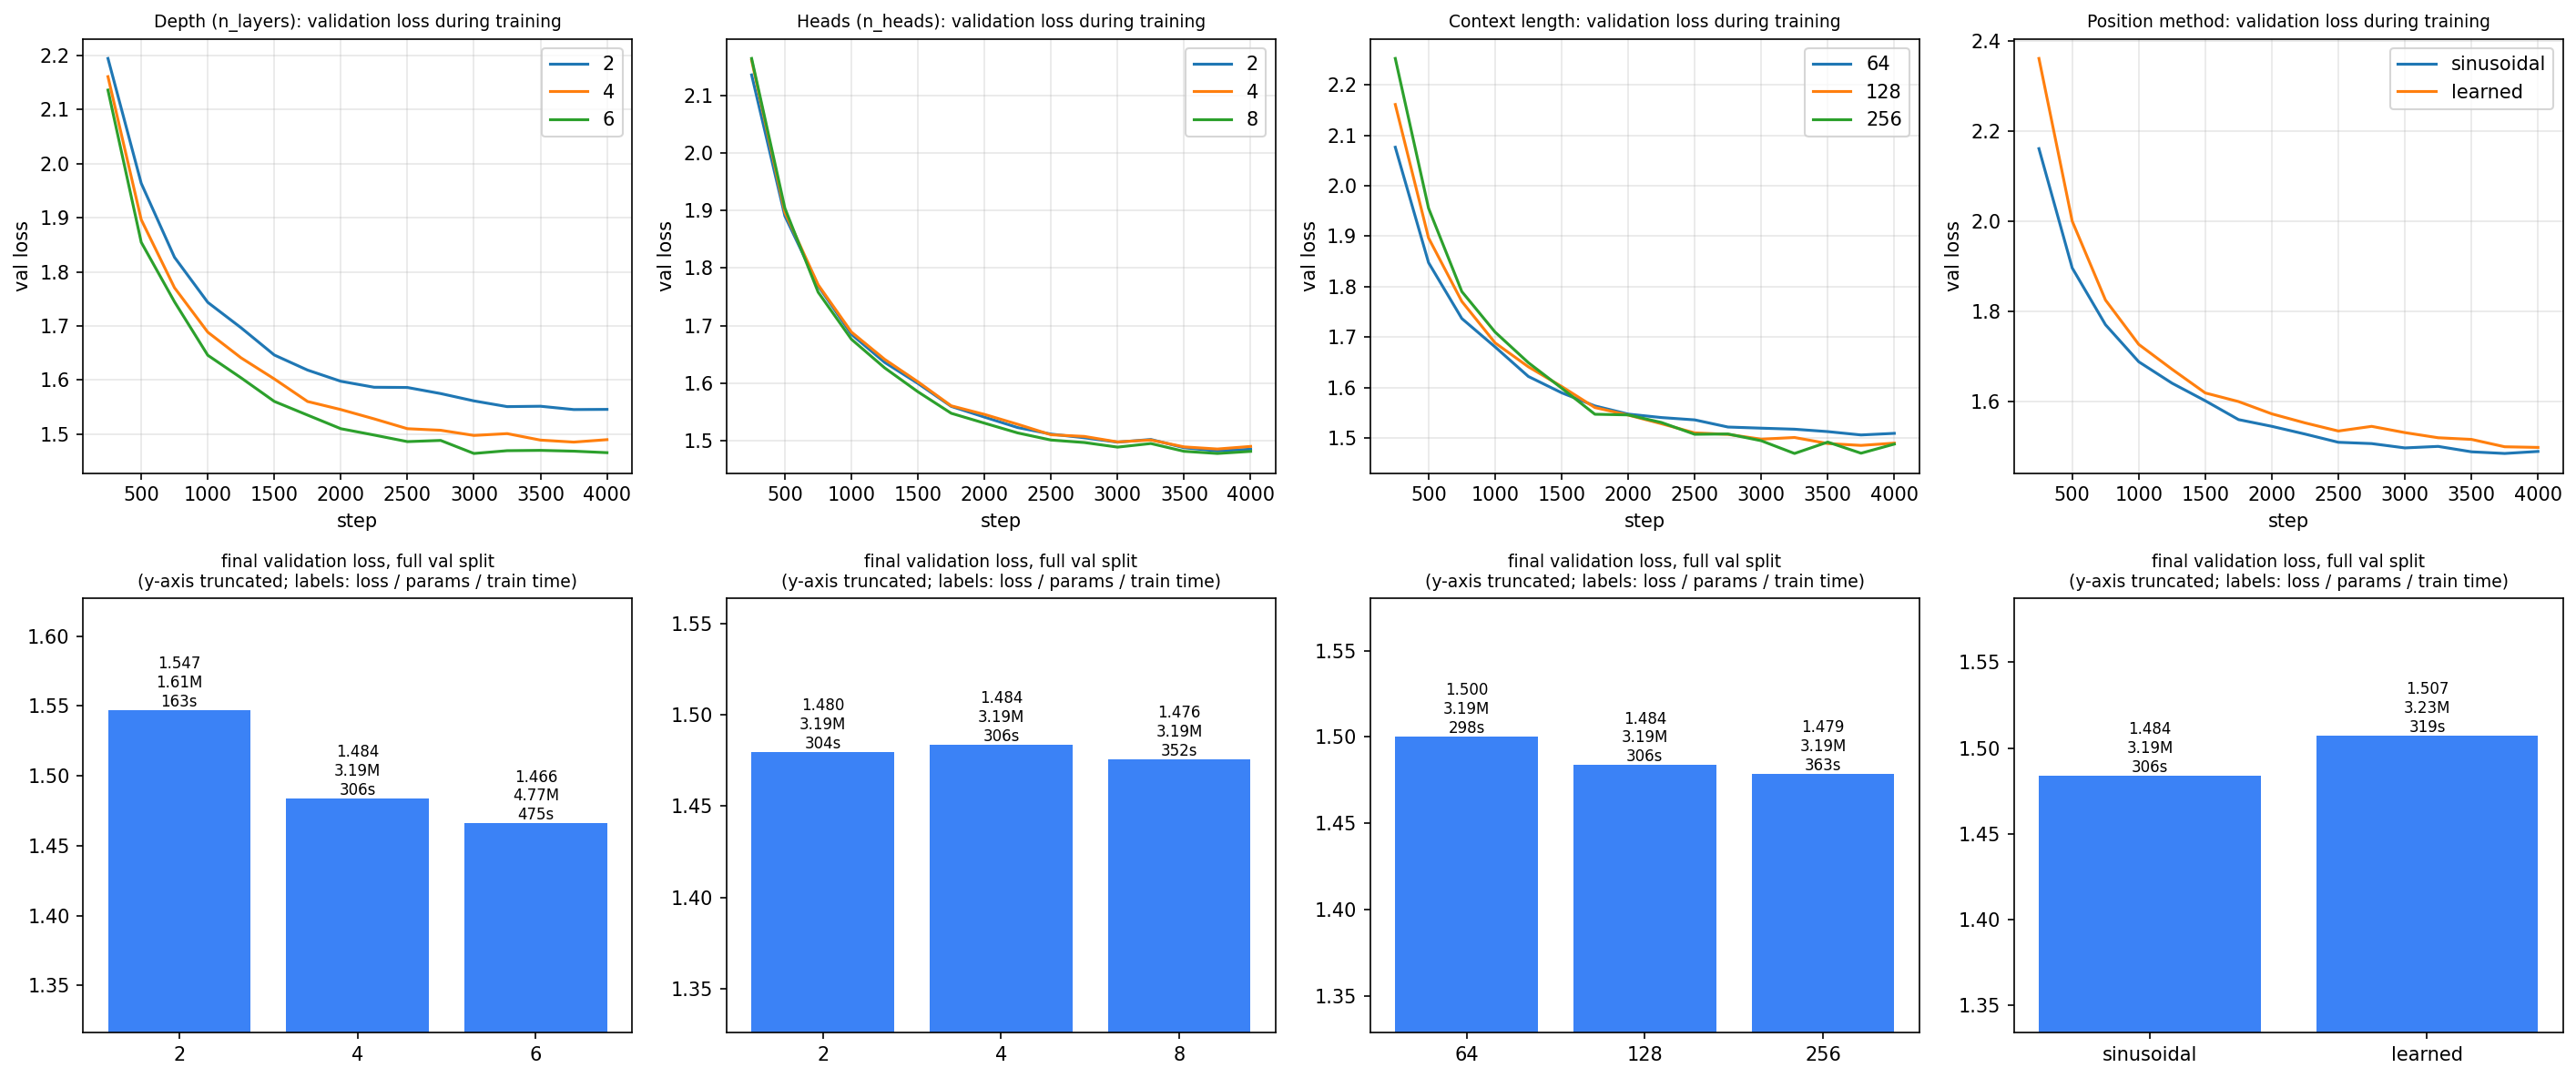

In [46]:
!python -m experiments.ablation
show('outputs/figures/fig06_train_val_loss.png', 'outputs/figures/fig09_ablation.png', width=1100)

In [47]:
display(Markdown(open("outputs/logs/ablation_table.md").read()))

| Experiment | Setting | Params | Batch x ctx | Final train loss | Val loss | Val ppl | Train time (s) | Tokens/s | Peak RSS (MB) |
|---|---|---|---|---|---|---|---|---|---|
| Depth (n_layers) | 2 | 1,613,312 | 64x128 | 1.320 | 1.547 | 4.70 | 163 | 201,414 | 439 |
| Depth (n_layers) | 4 | 3,192,832 | 64x128 | 1.210 | 1.484 | 4.41 | 306 | 107,224 | 794 |
| Depth (n_layers) | 6 | 4,772,352 | 64x128 | 1.148 | 1.466 | 4.33 | 475 | 68,955 | 1148 |
| Heads (n_heads) | 2 | 3,192,832 | 64x128 | 1.226 | 1.480 | 4.39 | 304 | 107,704 | 722 |
| Heads (n_heads) | 4 | 3,192,832 | 64x128 | 1.210 | 1.484 | 4.41 | 306 | 107,224 | 794 |
| Heads (n_heads) | 8 | 3,192,832 | 64x128 | 1.191 | 1.476 | 4.37 | 352 | 93,107 | 938 |
| Context length | 64 | 3,192,832 | 128x64 | 1.233 | 1.500 | 4.48 | 298 | 109,934 | 722 |
| Context length | 128 | 3,192,832 | 64x128 | 1.210 | 1.484 | 4.41 | 306 | 107,224 | 794 |
| Context length | 256 | 3,192,832 | 32x256 | 1.200 | 1.479 | 4.39 | 363 | 90,261 | 938 |
| Position method | sinusoidal | 3,192,832 | 64x128 | 1.210 | 1.484 | 4.41 | 306 | 107,224 | 794 |
| Position method | learned | 3,225,600 | 64x128 | 1.227 | 1.507 | 4.51 | 319 | 102,844 | 794 |


**Writing the analysis:** state *observations* first ("validation loss went from X to Y when depth increased from 2 to 6;
training time rose from A s to B s"), then separate *interpretations* ("the extra depth lets the model compose features, which would
explain ... - a hypothesis the data only partly supports because of one seed"). With a single seed, differences of a few
hundredths of a nat can be noise; say so, and if time allows repeat a run with another `seed` to estimate the spread.

### Optional: greedy vs temperature sampling
`experiments/evaluate.py` already compared greedy, T=0.5, 0.8 and 1.2 (distinct-word ratios and samples).

In [48]:
display(Markdown(open("outputs/samples/strategies.md").read()))

## greedy (T=0)  (distinct-1 0.20, distinct-2 0.26)
```
ROMEO:
I will not so much a soldier to the common of the
secret the sea of the sea to the courtesy.

BRUTUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

COR
```
## T=0.5  (distinct-1 0.74, distinct-2 0.96)
```
ROMEO:
Good my lord: lords, I'll say thee to thee;
The may say the better do what have seen them speak?

BUCKINGHAM:
No, my lord, I have stand to the grace of the sun
And son the worst of English will stay the duke
Of the senators of the ba
```
## T=0.8  (distinct-1 0.85, distinct-2 0.98)
```
ROMEO:
Good my lord: lord, let me like a three-pasting me.

AUTOLYCUS:
Romeo, sir; yet I will charge them go to come.

LUCIO:
Why, thou art as I the world?

CLARENCE:
Are son that very brothers like a fault droubt of death:
The very and sev
```
## T=1.2  (distinct-1 0.86, distinct-2 0.98)
```
ROMEO:
Go's not
To wills, I have so was a semble
Ready moes amongst me born: what my father boy,
He would gave it enjoy'd: but help me, that's gone
Make me swell thus hums.
not afivrs, I will villain! Laurence, at go;
Then say, thus armit
T
```


## 11. Failure analysis

Four measured limitations: (1) loss is higher at early positions where little context exists, (2) the model invents
non-words because it composes characters, (3) greedy decoding tends to loop, and (4) out-of-domain prompts get Shakespeare-style
nonsense. Pick at least two for the report and explain the likely causes (tiny model, short training, character-level tokens,
a narrow corpus, a 128-character window).

{
  "loss_first_8_positions": 1.8065634965896606,
  "loss_positions_8_to_32": 1.4758974313735962,
  "loss_last_half": 1.4636666774749756,
  "strategies": {
    "greedy": {
      "invented_word_rate": 0.008849557522123894,
      "repeated_4gram_rate": 0.7454545454545455
    },
    "T=0.8": {
      "invented_word_rate": 0.03065109941876477,
      "repeated_4gram_rate": 0.0
    },
    "T=1.2": {
      "invented_word_rate": 0.10269156398639398,
      "repeated_4gram_rate": 0.0
    }
  },
  "ood_invented_word_rate": {
    "def main():": 0.029411764705882353,
    "The future of artificial intelligence": 0.02702702702702703,
    "2 + 2 =": 0.03125,
    "Dear Sir or Madam,": 0.05405405405405406
  }
}
saved outputs/figures/fig_failure_modes.png


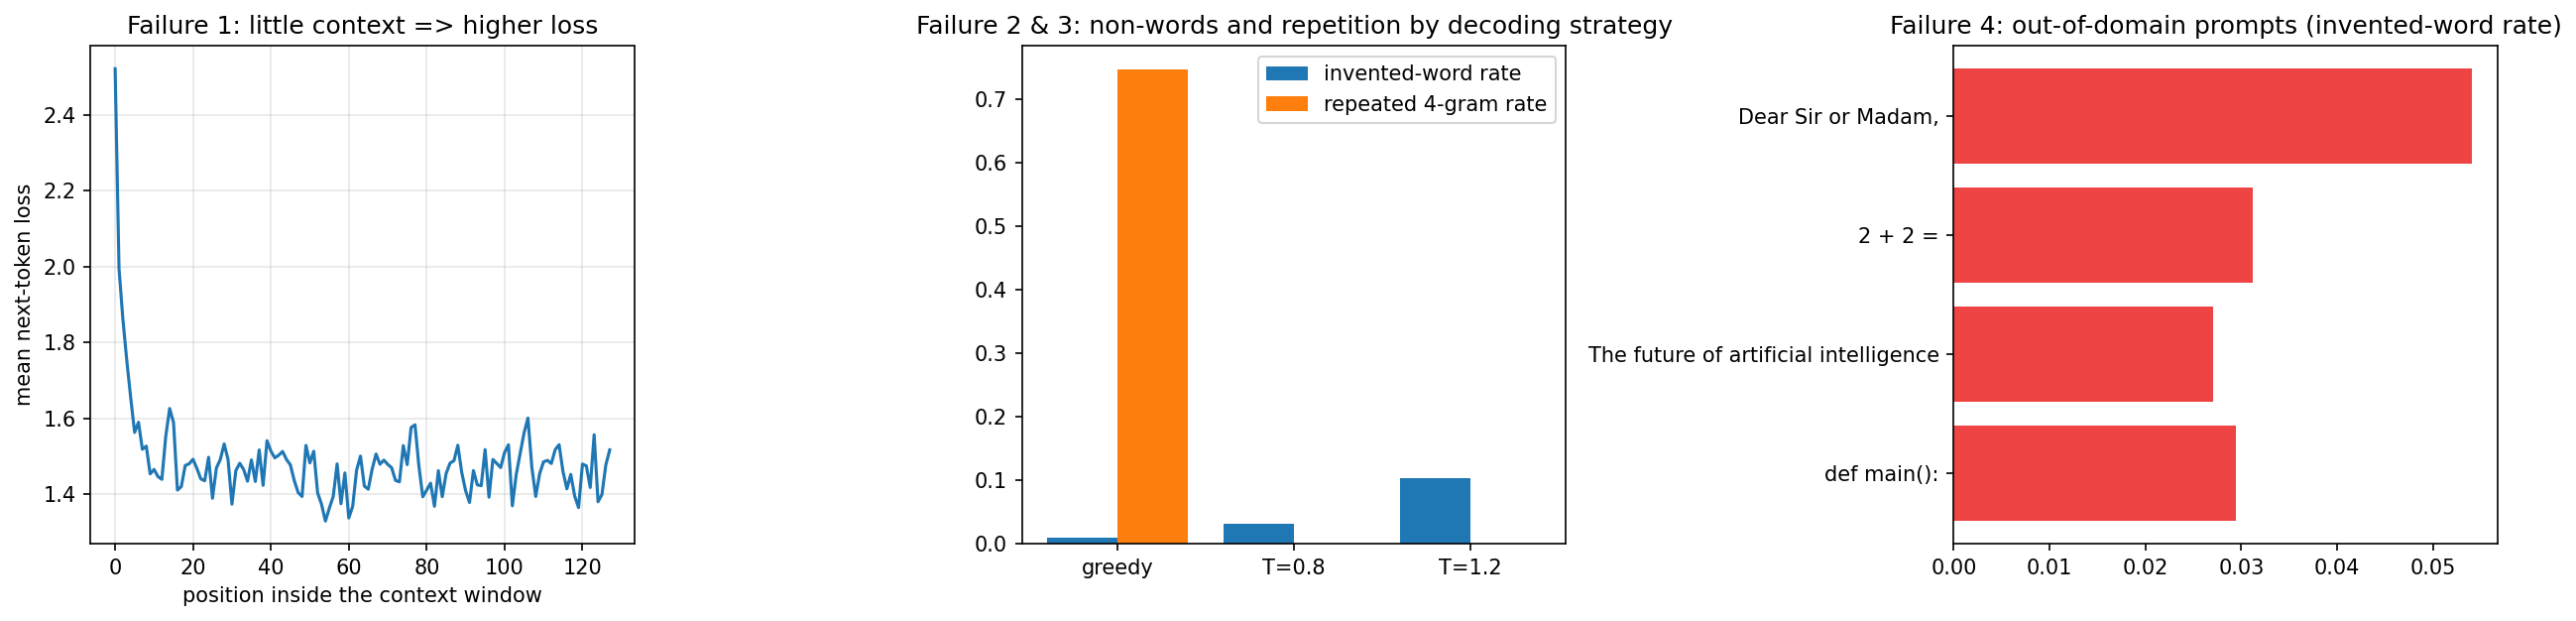

## Greedy decoding from 'ROMEO:'
```
ROMEO:
I will not so much a soldier to the common of the
secret the sea of the sea to the courtesy.

BRUTUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

CORIOLANUS:
I will not so.

C
```
## Out-of-domain prompt 'def main():'
```
def main: you must know so?

WARWICK:
Then would I let thee of thy heart;
For what he is beheld Bona, he that thou lords about
Return and death near for our purpose;
For
```
## Out-of-domain prompt 'The future of artificial intelligence'
```
The future of artificial intelligence
Shall be thy cheek and suffer'd thy fortune.
I pray thee, my lord, say, in come dear of winds,
The people mighting to the queen of them.

First Lord:
I say he 
```
## Out-of-domain prompt '2 + 2 ='
```
   mother, than the rest mor

In [49]:
!python -m experiments.failure_analysis
show("outputs/figures/fig_failure_modes.png", width=1100)
print(open("outputs/samples/failure_samples.md").read()[:2500])

## 12. Packaging - CLI and REST API

```
python -m src.generate --prompt "ROMEO:" --max-new-tokens 200 --temperature 0.8
uvicorn api:app --host 0.0.0.0 --port 8000
curl -X POST localhost:8000/generate -H "Content-Type: application/json" -d '{"prompt":"ROMEO:","seed":1}'
```
Figure 10 above shows both calls from this run. To **deploy on Render**: commit `checkpoints/baseline.pt` (about 13 MB at this size),
`api.py`, `src/`, `requirements-api.txt` and `render.yaml` to GitHub, then create a Blueprint from that repo. Keep the
live URL for the demo (step 8 of the demo script).

In [50]:
!python -m src.generate --checkpoint checkpoints/baseline.pt --prompt "The future of artificial intelligence" --max-new-tokens 80

Prompt: The future of artificial intelligence
Generated: The future of artificial intelligence:
The sword states and false cowards upon the eyes
Of you; but yet steal of natu

model parameters: 3.19M
context length: 128
temperature: 0.8


## 13. Submission acceptance tests (handout section 16)

In [51]:
import re, glob, subprocess, torch
from src.generate import load_model, generate_text
from experiments.evaluate import causal_check, PROMPTS
print("1-3. install / unit tests / tiny overfit:")
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], capture_output=True, text=True); print(r.stdout.strip().splitlines()[-1])
print("4. reload final checkpoint in a fresh object:")
model, tok2 = load_model("checkpoints/baseline.pt"); print("   params", f"{model.n_params():,}", "| context", model.cfg.context_length)
print("5. generate from three fixed prompts:")
for p in PROMPTS[:3]: print("  ", repr(p), "->", repr(generate_text(model, tok2, p, 60, 0.8, 40)[:90]))
print("6. causal correctness: max |dlogit| at earlier positions when future tokens change =", f"{causal_check(model):.2e}")
print("7. secrets scan:")
pat = re.compile(r"(api[_-]?key|secret|password|passwd|token)\s*[:=]\s*['\"][A-Za-z0-9_\-]{8,}", re.I)
hits = [f for f in glob.glob("**/*.py", recursive=True) + glob.glob("**/*.yaml", recursive=True) if pat.search(open(f, errors="ignore").read())]
print("   suspicious files:", hits or "none")

1-3. install / unit tests / tiny overfit:
15 passed in 3.99s
4. reload final checkpoint in a fresh object:
   params 3,192,832 | context 128
5. generate from three fixed prompts:
   'ROMEO:' -> 'ROMEO:\nSo it will be well most with your action.\n\nROMEO:\nWhy will '
   'To be, or not to be' -> 'To be, or not to be order who man at your royalty.\n\nBUCKINGHAM:\nDo you should t'
   'KING HENRY:\nWhat' -> 'KING HENRY:\nWhat, I were heard the Duke of Norfolk,\nWhen I am advised half o'
6. causal correctness: max |dlogit| at earlier positions when future tokens change = 0.00e+00
7. secrets scan:
   suspicious files: none


## 14. Numbers for the report
Copy these into the Medium article (hardware, parameter count, configuration, wall-clock time, losses, perplexity).

In [52]:
import json, torch
b = json.load(open("outputs/logs/baseline.json")); ev = json.load(open("outputs/logs/evaluation.json"))
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"hardware: {gpu}\nparameters: {b['params']:,}\nwall-clock training time: {b['wall_s']:.0f}s ({b['tokens_per_s']:,.0f} tokens/s, peak memory {b['peak_mem_mb']:.0f} MB)")
print("model config:", b["model_cfg"]); print("train config:", b["train_cfg"])
print(f"final train loss {b['final_train_loss']:.4f} | final val loss (random windows) {b['final_val_loss']:.4f}")
print(f"full-validation loss {ev['val_loss']:.4f} | perplexity {ev['val_perplexity']:.2f} | bits/char {ev['val_bits_per_char']:.3f}")

hardware: Tesla T4
parameters: 3,192,832
wall-clock training time: 348s (107,224 tokens/s, peak memory 794 MB)
model config: {'vocab_size': 65, 'context_length': 128, 'd_model': 256, 'n_heads': 4, 'n_layers': 4, 'ffn_mult': 4, 'dropout': 0.1, 'tie_weights': False, 'pos_type': 'sinusoidal', 'causal': True}
train config: {'optimizer': 'adamw', 'lr': 0.0006, 'weight_decay': 0.01, 'batch_size': 64, 'max_steps': 4000, 'eval_interval': 250, 'eval_iters': 40, 'warmup_steps': 150, 'seed': 1337, 'val_frac': 0.1}
final train loss 1.2098 | final val loss (random windows) 1.4899
full-validation loss 1.4838 | perplexity 4.41 | bits/char 2.141


In [53]:
# optional: keep results. Saves the checkpoint + outputs to Google Drive (for "checkpoint loadable from Drive") and downloads a zip.
import shutil
try:
    from google.colab import drive, files
    drive.mount("/content/drive")
    shutil.copytree("checkpoints", "/content/drive/MyDrive/minigpt/checkpoints", dirs_exist_ok=True)
    shutil.copytree("outputs", "/content/drive/MyDrive/minigpt/outputs", dirs_exist_ok=True)
    shutil.make_archive("minigpt_outputs", "zip", ".", "outputs"); files.download("minigpt_outputs.zip")
except Exception as e:
    print("not on Colab or Drive unavailable:", e)

Mounted at /content/drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
**References.** Vaswani et al. 2017, *Attention Is All You Need* (sinusoidal encoding, scaled dot-product and multi-head
attention). Radford et al. 2018/2019 (GPT, pre-LayerNorm style from GPT-2). Devlin et al. 2018 (BERT masked LM). Ba et al. 2016
(LayerNorm). Hendrycks & Gimpel 2016 (GELU). Tiny Shakespeare from Karpathy's char-rnn
(<https://github.com/karpathy/char-rnn>), as provided on Hugging Face. Add any tutorial you consulted here.